# Лабораторная работа №3. Кластеризация

**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи работы:**

1. Загрузить датасет для задачи кластеризации и провести дескриптивный анализ: размерность, типы признаков, пропуски, распределения.
2. Оценить информационную значимость признаков и проверить условия применимости кластеризации.
3. Обосновать метод масштабирования и привести данные к стандартному виду.
4. Визуально оценить структуру данных и аргументировать выбор алгоритмов.
5. Подобрать оптимальное число кластеров (метод локтя, силуэтный анализ, дендрограмма).
6. Выполнить кластеризацию двумя методами: K-средних и иерархическая кластеризация (метод Уорда).
7. Рассчитать внутренние и внешние метрики качества, расстояния между кластерами, компактность и центры.
8. Исследовать влияние параметров на качество разбиения.
9. Визуализировать результаты в пространстве главных компонент и содержательно интерпретировать кластеры.
10. Сравнить методы и сделать выводы о применимости.

**Датасет:** Wholesale customers (UCI Machine Learning Repository, ID 292) — годовые объёмы закупок 440 оптовых клиентов.

## 1. Введение

Кластеризация — это обучение без учителя: алгоритм разбивает объекты на группы так, чтобы объекты внутри группы были похожи, а между группами — различны. В отличие от классификации, здесь заранее не известны ни число групп, ни их состав, поэтому центральную роль играют:

* корректная предобработка (масштаб признаков напрямую влияет на метрику расстояния);
* обоснованный выбор числа кластеров;
* набор метрик качества — как внутренних (не требующих истинных меток), так и внешних (сравнивающих разбиение с известной разметкой);
* содержательная интерпретация результата: кластеры должны иметь смысл для заказчика, а не только высокий формальный балл.

В работе используется датасет оптовых закупок. Задача кластеризации здесь вполне практическая: сегментировать клиентов по структуре закупок, чтобы отдел продаж мог предлагать разные условия розничным сетям и предприятиям общепита. Известный признак `Channel` (канал сбыта) в обучении **не участвует** — он применяется только на последнем этапе для внешней валидации, как того требует методика.

### 1.1. Используемые библиотеки и настройки

Фиксируем `RANDOM_STATE = 42`, чтобы все результаты воспроизводились при повторном запуске ноутбука.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, cdist

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, rand_score,
    homogeneity_score, completeness_score, v_measure_score,
    normalized_mutual_info_score,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

print('Версии: numpy', np.__version__, '| pandas', pd.__version__)
import sklearn
print('scikit-learn', sklearn.__version__)

Версии: numpy 2.4.3 | pandas 3.0.6
scikit-learn 1.9.1


**Пояснение.** Используются только стандартные библиотеки из рекомендаций к работе: `pandas`/`numpy` для данных, `scikit-learn` для масштабирования, кластеризации и метрик, `matplotlib`/`seaborn` для графиков. Дополнительно `scipy` (дендрограмма, расстояния, проверка нормальности) и `statsmodels` (VIF — фактор инфляции дисперсии).

## 2. Описание датасета

**Источник:** UCI Machine Learning Repository, *Wholesale customers data set* (ID 292).
Данные собраны по клиентам оптового дистрибьютора; каждая строка — один клиент, признаки — годовые траты по товарным категориям в денежных единицах (д.е.). Выбран UCI, а не Kaggle: это первичный источник с фиксированным составом из 440 записей и открытой лицензией, тогда как на Kaggle встречаются производные копии с изменённой предобработкой.

| Столбец | Смысл |
|---|---|
| `Channel` | канал сбыта: 1 — HoReCa (отели, рестораны, кафе), 2 — розничная торговля |
| `Region` | регион: 1 — Лиссабон, 2 — Порту, 3 — прочие |
| `Fresh` | свежие продукты |
| `Milk` | молочные продукты |
| `Grocery` | бакалея |
| `Frozen` | замороженные продукты |
| `Detergents_Paper` | моющие средства и бумага |
| `Delicassen` | деликатесы (в оригинале — `Delicassen`) |

`Channel` и `Region` — категориальные метаданные. В кластеризации они **не используются**, но `Channel` понадобится для внешней валидации, поэтому сохраним его отдельно.

### 2.1. Загрузка данных

Ноутбук сначала ищет локальную копию `data/wholesale_customers.csv` (она приложена к работе), а при её отсутствии скачивает файл с сервера UCI. Так отчёт воспроизводится и без доступа к интернету.

In [2]:
DATA_PATH = Path('data/wholesale_customers.csv')
DATA_URL = ('https://archive.ics.uci.edu/ml/machine-learning-databases/'
            '00292/Wholesale%20customers%20data.csv')

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False, encoding='utf-8')

df = pd.read_csv(DATA_PATH)

FEATURES = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
CHANNEL_NAMES = {1: 'HoReCa', 2: 'Retail'}

df['Channel_name'] = df['Channel'].map(CHANNEL_NAMES)

print('Размер датасета:', df.shape)
print('Признаки для кластеризации:', FEATURES)
display(df.head())

Размер датасета: (440, 9)
Признаки для кластеризации: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel_name
0,2,3,12669,9656,7561,214,2674,1338,Retail
1,2,3,7057,9810,9568,1762,3293,1776,Retail
2,2,3,6353,8808,7684,2405,3516,7844,Retail
3,1,3,13265,1196,4221,6404,507,1788,HoReCa
4,2,3,22615,5410,7198,3915,1777,5185,Retail


### 2.2. Первичный осмотр: типы, пропуски, описательные статистики

In [3]:
info = pd.DataFrame({
    'Тип данных': df.dtypes.astype(str),
    'Уникальных значений': df.nunique(),
    'Пропусков': df.isna().sum(),
    'Пропусков, %': (df.isna().mean() * 100).round(2),
})
display(info)

print('Полных дубликатов строк:', df.duplicated().sum())
print()
display(df[FEATURES].describe().T.round(1))

,Тип данных,Уникальных значений,Пропусков,"Пропусков, %"
Channel,int64,2,0,0.0
Region,int64,3,0,0.0
Fresh,int64,433,0,0.0
Milk,int64,421,0,0.0
Grocery,int64,430,0,0.0
Frozen,int64,426,0,0.0
Detergents_Paper,int64,417,0,0.0
Delicassen,int64,403,0,0.0
Channel_name,str,2,0,0.0


Полных дубликатов строк: 0



,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,12000.3,12647.3,3.0,3127.8,8504.0,16933.8,112151.0
Milk,440.0,5796.3,7380.4,55.0,1533.0,3627.0,7190.2,73498.0
Grocery,440.0,7951.3,9503.2,3.0,2153.0,4755.5,10655.8,92780.0
Frozen,440.0,3071.9,4854.7,25.0,742.2,1526.0,3554.2,60869.0
Detergents_Paper,440.0,2881.5,4767.9,3.0,256.8,816.5,3922.0,40827.0
Delicassen,440.0,1524.9,2820.1,3.0,408.2,965.5,1820.2,47943.0


**Пояснение.** Датасет компактный: **440 наблюдений, 8 исходных столбцов**, пропусков и дубликатов нет — дополнительная очистка не требуется. Все шесть признаков — количественные, непрерывные, измерены в одних единицах (д.е. в год), но в очень разных диапазонах: `Fresh` — от 3 до 112 151, `Delicassen` — от 3 до 47 943.

Обратите внимание на расхождение среднего и медианы. Например, у `Delicassen` среднее 1 525 при медиане около 966, у `Fresh` — 12 000 против 8 504. Это первый сигнал сильной правосторонней асимметрии: небольшая часть очень крупных клиентов «тянет» среднее вверх. Такое распределение типично для денежных показателей и требует отдельного решения при предобработке.

### 2.3. Распределение признаков и проверка на нормальность

Строим гистограммы с ядерной оценкой плотности, а также проверяем нормальность тремя способами: визуально (гистограмма, QQ-график), по коэффициентам асимметрии/эксцесса и формальным критерием Шапиро–Уилка.

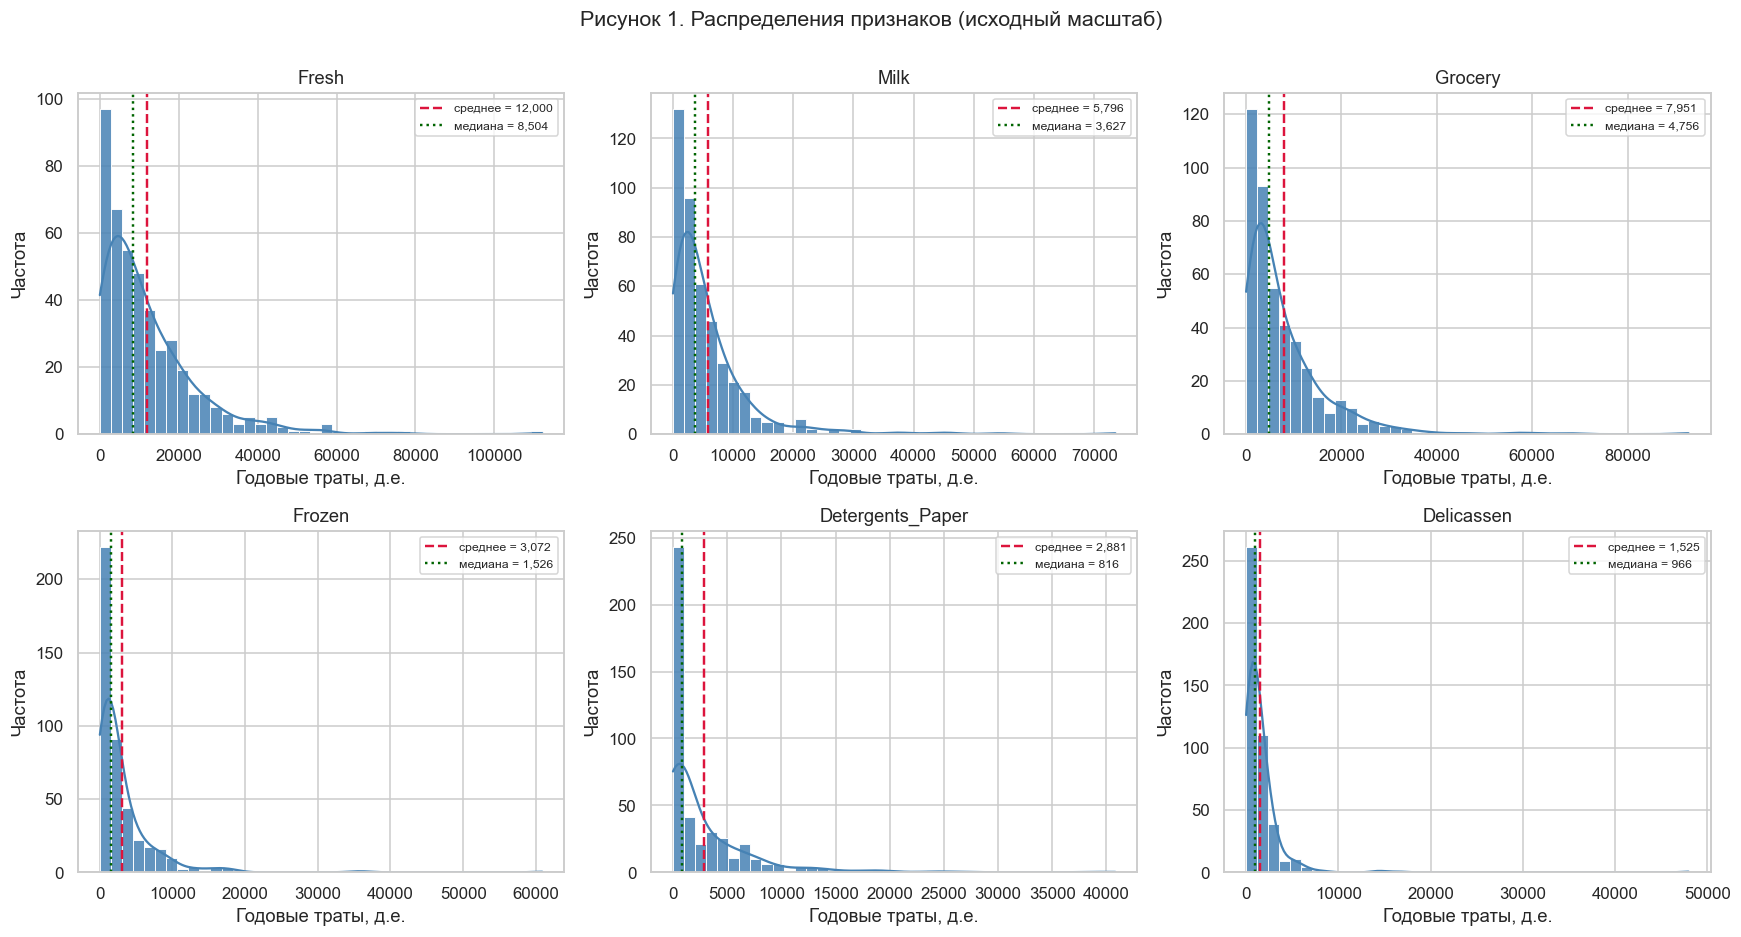

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df[col], bins=40, kde=True, ax=ax,
                 color='steelblue', edgecolor='white', alpha=0.85)
    ax.axvline(df[col].mean(), color='crimson', ls='--', lw=1.6,
               label=f'среднее = {df[col].mean():,.0f}')
    ax.axvline(df[col].median(), color='darkgreen', ls=':', lw=1.6,
               label=f'медиана = {df[col].median():,.0f}')
    ax.set_title(col)
    ax.set_xlabel('Годовые траты, д.е.')
    ax.set_ylabel('Частота')
    ax.legend(fontsize=8)

fig.suptitle('Рисунок 1. Распределения признаков (исходный масштаб)', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

**Пояснение к рисунку 1.** Все шесть распределений имеют классическую форму «правого хвоста»: основная масса клиентов сосредоточена в левой части графика, а немногочисленные крупные оптовики образуют длинный хвост. Медиана везде заметно меньше среднего. Ни один признак не похож на нормально распределённый: максимум в области малых значений и постепенное затухание — это логнормальная или близкая к ней форма.

Именно поэтому применять k-means «как есть» нельзя: центроид будет смещён в сторону хвоста, а несколько гигантов будут определять границы кластеров.

,Асимметрия,Эксцесс,p-value Шапиро,Асимметрия после log,p-value после log
Признак,,,,,
Fresh,2.56,11.54,7.9e-24,-1.58,7.1e-17
Milk,4.05,24.67,9.8e-30,-0.22,9.0e-02
Grocery,3.59,20.91,3.9e-28,-0.67,3.5e-08
Frozen,5.91,54.69,1.3e-32,-0.35,5.5e-03
Detergents_Paper,3.63,19.01,1.9e-30,-0.24,3.6e-05
Delicassen,11.15,170.69,1.8e-36,-1.09,9.0e-13


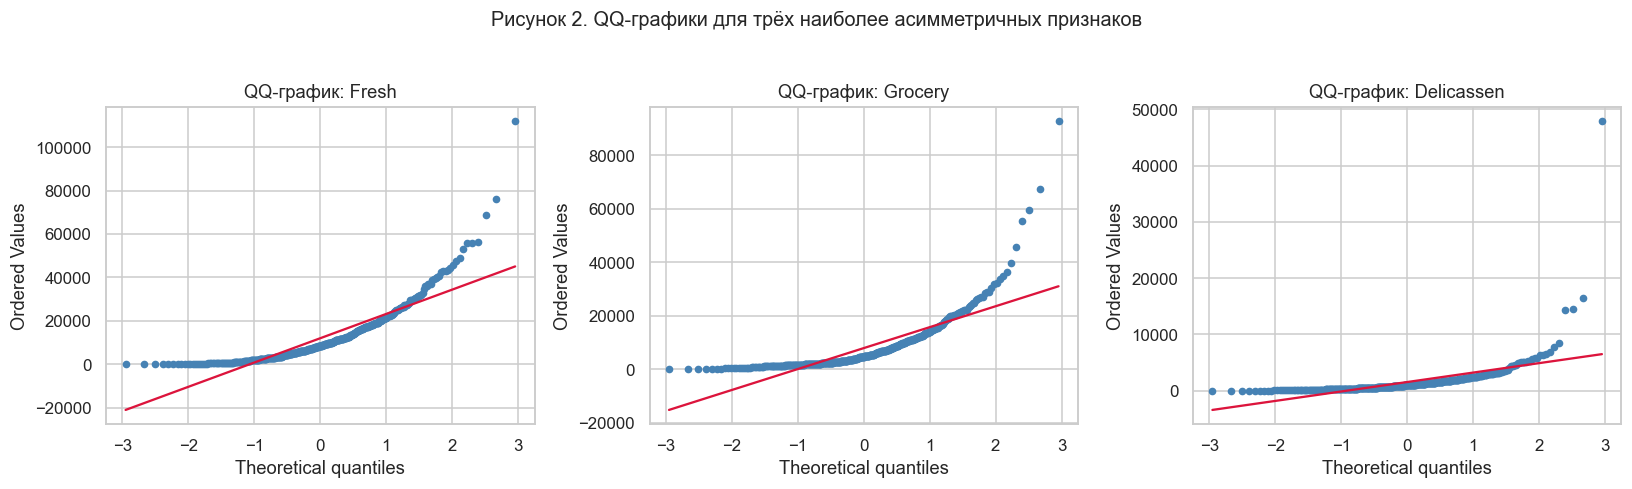

In [5]:
rows = []
for col in FEATURES:
    raw = df[col]
    log = np.log1p(raw)
    rows.append({
        'Признак': col,
        'Асимметрия': raw.skew(),
        'Эксцесс': raw.kurt(),
        'p-value Шапиро': f'{stats.shapiro(raw)[1]:.1e}',
        'Асимметрия после log': log.skew(),
        'p-value после log': f'{stats.shapiro(log)[1]:.1e}',
    })
normality = pd.DataFrame(rows).set_index('Признак')
display(normality.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, col in zip(axes, ['Fresh', 'Grocery', 'Delicassen']):
    stats.probplot(df[col], dist='norm', plot=ax)
    ax.set_title(f'QQ-график: {col}')
    ax.get_lines()[0].set_markersize(4)
    ax.get_lines()[0].set_color('steelblue')
    ax.get_lines()[1].set_color('crimson')
fig.suptitle('Рисунок 2. QQ-графики для трёх наиболее асимметричных признаков', y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

**Пояснение.** Формальный критерий Шапиро–Уилка отвергает гипотезу о нормальности для всех признаков (p-value порядка 10⁻²⁴ и меньше). QQ-графики подтверждают: точки сильно отклоняются от прямой в правой верхней части — это и есть тяжёлый правый хвост.

Логарифмирование `log1p` (натуральный логарифм от значения плюс единица) резко улучшает картину:

* асимметрия падает с 2,6–11,2 до −1,6…−0,2, то есть распределения становятся почти симметричными (лёгкий левый скос — плата за сжатие больших значений);
* для `Milk` гипотеза о нормальности после преобразования уже **не отвергается** (p ≈ 0,09);
* для остальных признаков нормальность всё ещё не достигается, но это нормально: критерий Шапиро очень чувствителен при n = 440, а для кластеризации важна не строгая нормальность, а симметрия и отсутствие экстремальных выбросов.

Вывод: преобразование `log1p` обосновано и будет применено перед масштабированием.

### 2.4. Анализ выбросов

Выбросы ищем двумя способами: по правилу 1,5·IQR (межквартильный размах) и по стандартизованному отклонению |z| > 3.

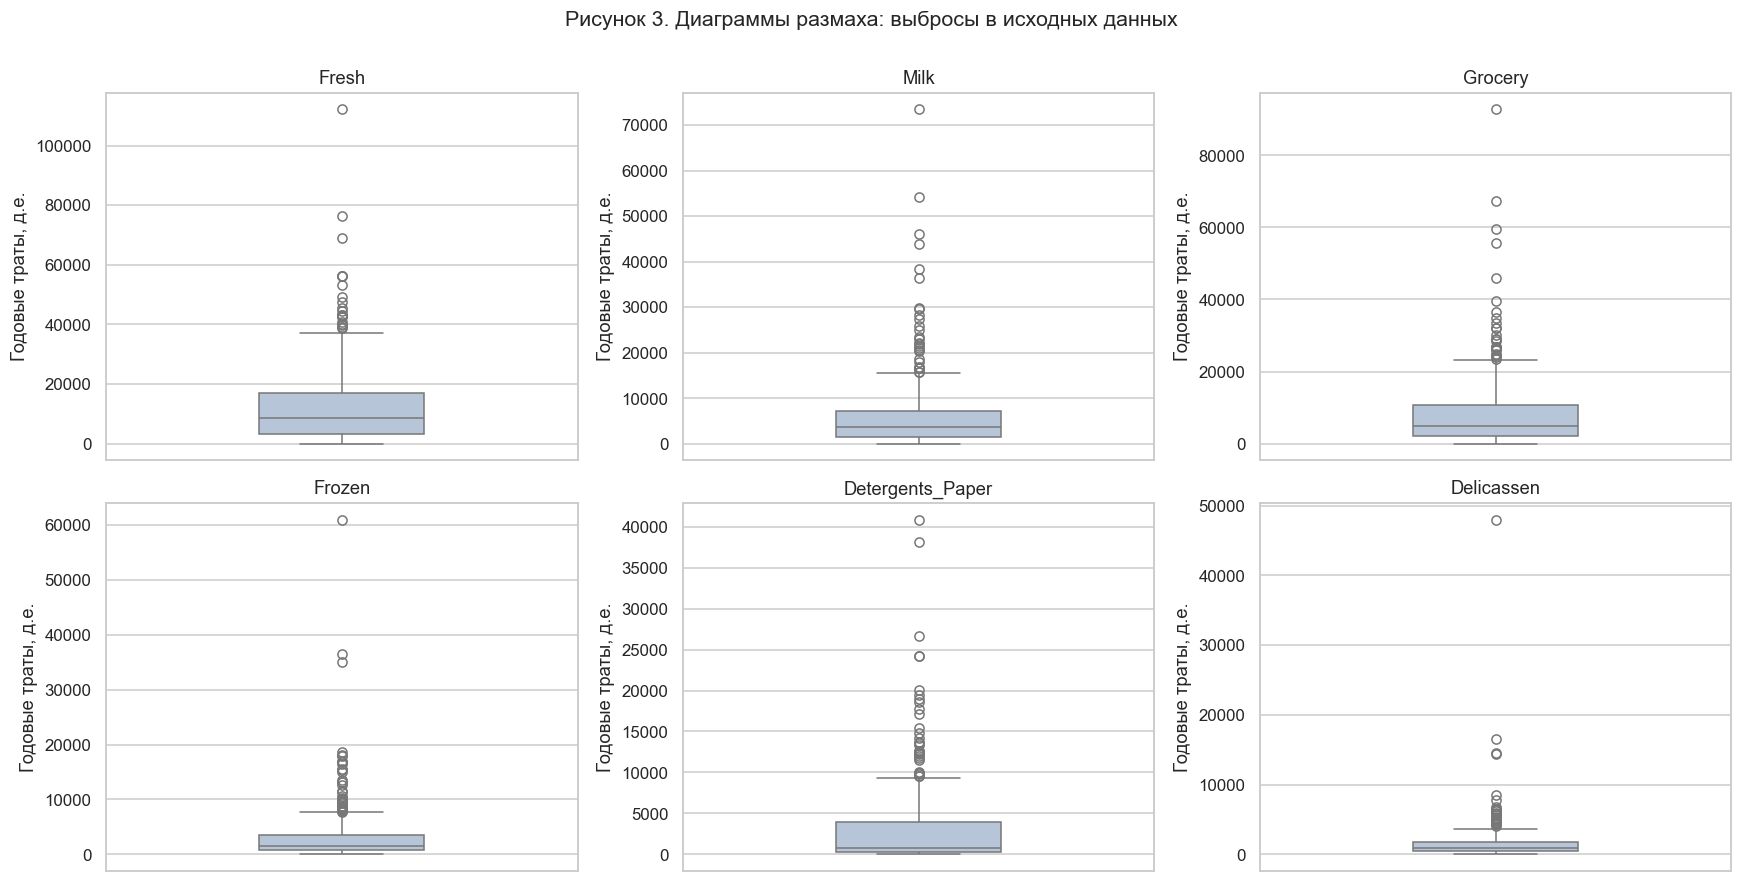

,Выбросов по IQR,"Доля, %",Выбросов по |z| > 3
Fresh,20,4.5,7
Milk,28,6.4,9
Grocery,24,5.5,7
Frozen,43,9.8,6
Detergents_Paper,30,6.8,10
Delicassen,27,6.1,4


Всего значений-выбросов по IQR: 172 из 2640
Клиентов хотя бы с одним выбросом: 108 из 440 (24.5%)

Пять клиентов с максимальными закупками Fresh:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel_name
181,112151,29627,18148,16745,4948,8550,HoReCa
125,76237,3473,7102,16538,778,918,HoReCa
284,68951,4411,12609,8692,751,2406,HoReCa
39,56159,555,902,10002,212,2916,HoReCa
258,56083,4563,2124,6422,730,3321,HoReCa


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue', width=0.35)
    ax.set_title(col)
    ax.set_ylabel('Годовые траты, д.е.')
fig.suptitle('Рисунок 3. Диаграммы размаха: выбросы в исходных данных', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

q1, q3 = df[FEATURES].quantile(0.25), df[FEATURES].quantile(0.75)
iqr = q3 - q1
out_iqr = (df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)
z_scores = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
out_z = z_scores.abs() > 3

outliers = pd.DataFrame({
    'Выбросов по IQR': out_iqr.sum(),
    'Доля, %': (out_iqr.mean() * 100).round(1),
    'Выбросов по |z| > 3': out_z.sum(),
})
display(outliers)

print('Всего значений-выбросов по IQR:', int(out_iqr.values.sum()), 'из', out_iqr.size)
print('Клиентов хотя бы с одним выбросом:',
      int(out_iqr.any(axis=1).sum()), 'из', len(df),
      f'({out_iqr.any(axis=1).mean() * 100:.1f}%)')
print()
print('Пять клиентов с максимальными закупками Fresh:')
display(df.nlargest(5, 'Fresh')[['Fresh', 'Milk', 'Grocery', 'Frozen',
                                 'Detergents_Paper', 'Delicassen', 'Channel_name']])

**Пояснение.** По правилу 1,5·IQR выбросы есть во всех признаках: от 20 (`Fresh`) до 43 (`Frozen`) значений, суммарно 172 значения. Хотя бы один выброс имеет **108 клиентов из 440 (24,5 %)**. Критерий |z| > 3 даёт гораздо меньше точек (4–10 на признак), потому что сам по себе чувствителен к тяжёлому хвосту.

Ключевой вопрос: **что делать с этими выбросами?**

Формально это выбросы, но по смыслу — реальные крупные оптовики, а не ошибки ввода. Если их удалить, мы выбросим как раз тех клиентов, которые образуют отдельный сегмент «розничные сети», и кластерная структура разрушится. Поэтому принимаем решение:

1. **не удалять** объекты, а ослабить влияние хвоста логарифмированием;
2. проверить устойчивость результата на `RobustScaler`, который использует медиану и межквартильный размах и почти не чувствителен к выбросам;
3. при интерпретации помнить, что центры кластеров смещены крупными клиентами.

## 3. Информационная значимость признаков

Чтобы понять, какие признаки действительно несут информацию, оценим:

* разброс и коэффициент вариации — насколько признак различает клиентов;
* корреляционную матрицу — нет ли дублирующих признаков;
* VIF (фактор инфляции дисперсии) — количественная мера мультиколлинеарности;
* метод главных компонент — сколько независимых направлений изменчивости есть в данных.

,Среднее,Медиана,СКО,Коэф. вариации,Мин,Макс,Размах
Fresh,12000.30,8504.0,12647.33,1.05,3,112151,112148
Milk,5796.27,3627.0,7380.38,1.27,55,73498,73443
Grocery,7951.28,4755.5,9503.16,1.20,3,92780,92777
Frozen,3071.93,1526.0,4854.67,1.58,25,60869,60844
Detergents_Paper,2881.49,816.5,4767.85,1.65,3,40827,40824
Delicassen,1524.87,965.5,2820.11,1.85,3,47943,47940


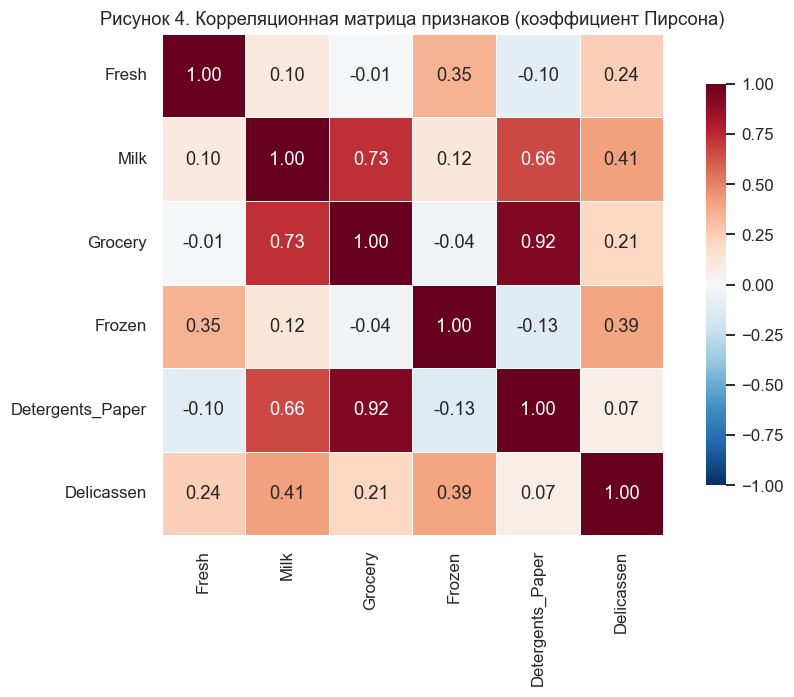

In [7]:
spread = pd.DataFrame({
    'Среднее': df[FEATURES].mean(),
    'Медиана': df[FEATURES].median(),
    'СКО': df[FEATURES].std(),
    'Коэф. вариации': df[FEATURES].std() / df[FEATURES].mean(),
    'Мин': df[FEATURES].min(),
    'Макс': df[FEATURES].max(),
    'Размах': df[FEATURES].max() - df[FEATURES].min(),
})
display(spread.round(2))

fig, ax = plt.subplots(figsize=(9, 6.5))
corr = df[FEATURES].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Рисунок 4. Корреляционная матрица признаков (коэффициент Пирсона)')
plt.tight_layout()
plt.show()

**Пояснение.** Коэффициенты вариации превышают 1 у всех признаков — значит, разброс сравним со средним или больше него, то есть признаки хорошо различают клиентов (низкая вариативность была бы поводом исключить признак как неинформативный).

Корреляционная матрица показывает главное:

* `Grocery` и `Detergents_Paper` — **r = 0,92**, почти линейная зависимость: клиент, закупающий бакалею, почти всегда берёт и бытовую химию;
* `Milk`–`Grocery` — 0,73, `Milk`–`Detergents_Paper` — 0,66;
* `Fresh` и `Grocery` практически не связаны (r ≈ −0,01), зато `Fresh`–`Frozen` — 0,35.

Отсюда гипотеза о двух «корзинах»: «свежие + заморозка» (общепит) и «бакалея + химия + молоко» (розница). Проверим её формально.

In [8]:
def vif_table(data):
    values = data.values.astype(float)
    return pd.Series(
        {col: variance_inflation_factor(values, i) for i, col in enumerate(data.columns)},
        name='VIF',
    )

vif_raw = vif_table(df[FEATURES])
vif_log = vif_table(np.log1p(df[FEATURES])).rename('VIF после log1p')

vif = pd.concat([vif_raw, vif_log], axis=1)
vif['Интерпретация'] = np.where(vif['VIF после log1p'] > 5, 'высокая',
                        np.where(vif['VIF после log1p'] > 2.5, 'умеренная', 'низкая'))
display(vif.round(2))

,VIF,VIF после log1p,Интерпретация
Fresh,1.18,1.24,низкая
Milk,2.55,2.67,умеренная
Grocery,8.79,3.68,умеренная
Frozen,1.32,1.27,низкая
Detergents_Paper,8.10,2.93,умеренная
Delicassen,1.52,1.29,низкая


**Пояснение.** До преобразования VIF у `Grocery` (8,8) и `Detergents_Paper` (8,1) превышает порог 5–10, то есть мультиколлинеарность высокая: эти два признака несут почти одну и ту же информацию. После логарифмирования показатели снижаются до 3,7 и 2,9 — умеренный уровень, работать с признаками можно.

Для k-means и иерархической кластеризации мультиколлинеарность не является критичной (она не ломает алгоритм, как в регрессии), но она означает, что евклидово расстояние усиливает вес «розничной корзины»: три коррелированных признака вместо одного. Это надо учитывать при интерпретации и при переходе к главным компонентам.

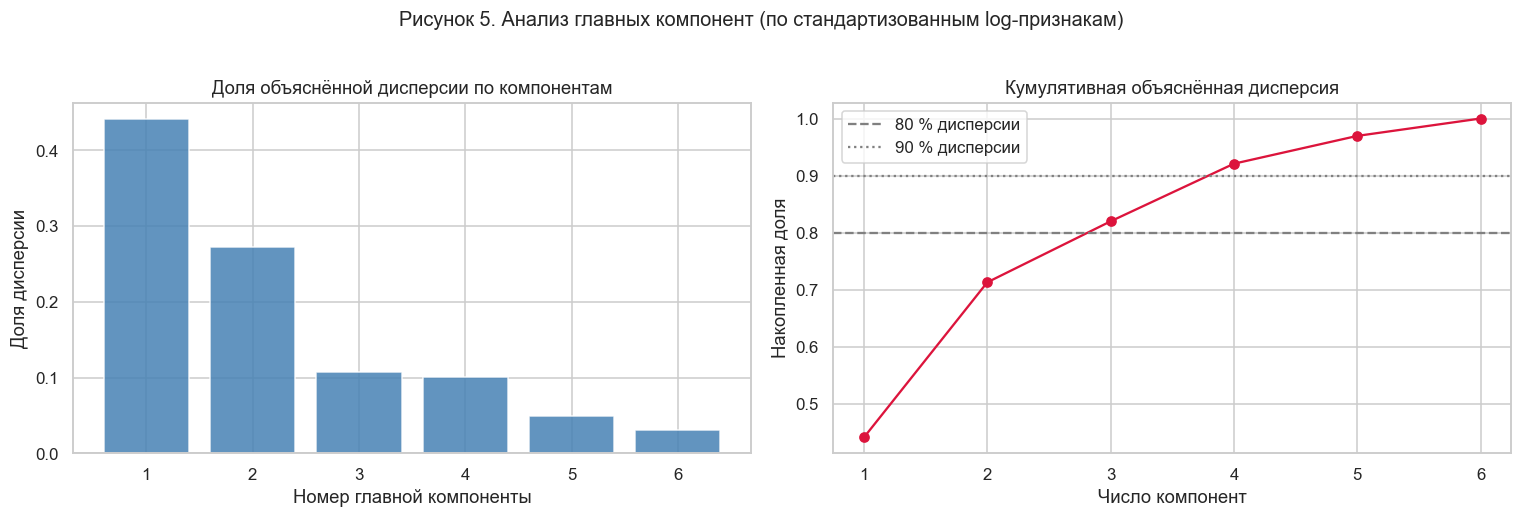

,PC1,PC2
Fresh,-0.11,0.59
Milk,0.54,0.13
Grocery,0.57,-0.01
Frozen,-0.14,0.59
Detergents_Paper,0.55,-0.07
Delicassen,0.21,0.53


PC1 + PC2 объясняют: 71.3 % дисперсии
PC1 + PC2 + PC3 объясняют: 82.0 % дисперсии


In [9]:
pca_probe = PCA().fit(StandardScaler().fit_transform(np.log1p(df[FEATURES])))
evr = pca_probe.explained_variance_ratio_
cum = np.cumsum(evr)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].bar(range(1, len(evr) + 1), evr, color='steelblue', alpha=0.85)
axes[0].set_title('Доля объяснённой дисперсии по компонентам')
axes[0].set_xlabel('Номер главной компоненты')
axes[0].set_ylabel('Доля дисперсии')

axes[1].plot(range(1, len(evr) + 1), cum, 'o-', color='crimson')
axes[1].axhline(0.8, ls='--', color='gray', label='80 % дисперсии')
axes[1].axhline(0.9, ls=':', color='gray', label='90 % дисперсии')
axes[1].set_title('Кумулятивная объяснённая дисперсия')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Накопленная доля')
axes[1].legend()

fig.suptitle('Рисунок 5. Анализ главных компонент (по стандартизованным log-признакам)', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca_probe.components_[:2].T, index=FEATURES, columns=['PC1', 'PC2'])
display(loadings.round(2))
print('PC1 + PC2 объясняют: {:.1f} % дисперсии'.format((evr[:2].sum()) * 100))
print('PC1 + PC2 + PC3 объясняют: {:.1f} % дисперсии'.format((evr[:3].sum()) * 100))

**Пояснение.** Первая компонента объясняет **44,1 %** дисперсии, вторая — **27,2 %**, вместе — **71,3 %**, три компоненты — 82 %. Значит, для двумерной визуализации достаточно первых двух компонент: они сохраняют почти три четверти информации.

Нагрузки читаются очень содержательно:

* **PC1** — «розничная корзина»: высокие положительные вклады у `Milk` (0,54), `Grocery` (0,57), `Detergents_Paper` (0,55);
* **PC2** — «HoReCa-корзина»: `Fresh` (0,59), `Frozen` (0,59), `Delicassen` (0,53).

То есть данные естественно описываются двумя осями: «розничные против общепитовских закупок». Это заранее подсказывает, что осмысленных кластеров, скорее всего, два, и что они будут разделяться прежде всего составом корзины, а не общим объёмом закупок.

## 4. Проверка условий применимости кластеризации

Методика требует проверить три условия. Оформим их явным чек-листом.

| Условие | Проверка | Вывод |
|---|---|---|
| **Отсутствие классов в обучении** | `Channel` и `Region` исключены из матрицы признаков; используются только после кластеризации для внешней валидации | выполнено |
| **Осмысленность кластеризации** | Признаки — структура закупок; гипотеза о сегментах «розница / общепит» подтверждается корреляциями и PCA (PC1 и PC2) | выполнено |
| **Отсутствие (обработанных) выбросов** | Выбросы есть, но являются реальными крупными клиентами; влияние ослаблено `log1p`, устойчивость проверяется `RobustScaler` | выполнено с оговоркой |
| **Пропуски и дубликаты** | 0 пропусков, 0 дубликатов | выполнено |

Единственное ограничение — выбросы не удалены, а трансформированы. Это осознанное решение: удаление «выбросов» здесь означало бы удаление наиболее ценного сегмента. В разделе 14 будет показано, что результат на `RobustScaler` согласуется с основным (ARI 0,93 и 0,87), то есть выводы устойчивы.

In [10]:
print('Распределение канала сбыта (только для внешней валидации, в обучении не используется):')
display(df['Channel_name'].value_counts().to_frame('Клиентов'))
display((df['Channel_name'].value_counts(normalize=True) * 100).round(1).to_frame('Доля, %'))
print('Распределение региона (справочно):')
display(df['Region'].value_counts().sort_index().to_frame('Клиентов'))

assert df[FEATURES].isna().sum().sum() == 0, 'Найдены пропуски'
assert df.duplicated().sum() == 0, 'Найдены дубликаты'
print('Проверки пройдены: пропусков и дубликатов нет.')

Распределение канала сбыта (только для внешней валидации, в обучении не используется):


,Клиентов
Channel_name,
HoReCa,298
Retail,142


,"Доля, %"
Channel_name,
HoReCa,67.7
Retail,32.3


Распределение региона (справочно):


,Клиентов
Region,
1,77
2,47
3,316


Проверки пройдены: пропусков и дубликатов нет.


**Пояснение.** Классы несбалансированы: 298 клиентов общепита (HoReCa) против 142 розничных (68 % / 32 %). Это важно для внешних метрик: индекс Rand в такой ситуации будет завышен, поэтому основным внешним показателем выберем ARI, учитывающий случайное согласие.

## 5. Предобработка данных

### 5.1. Логарифмирование

Основание логарифма не важно (меняется только масштаб), поэтому используем натуральный `log1p(x) = ln(1 + x)`. В данных минимальные траты равны 3, поэтому `log(x)` дал бы практически тот же результат; `log1p` выбран для универсальности — он корректен и при возможных нулевых значениях, что важно при повторном использовании кода на других выборках.

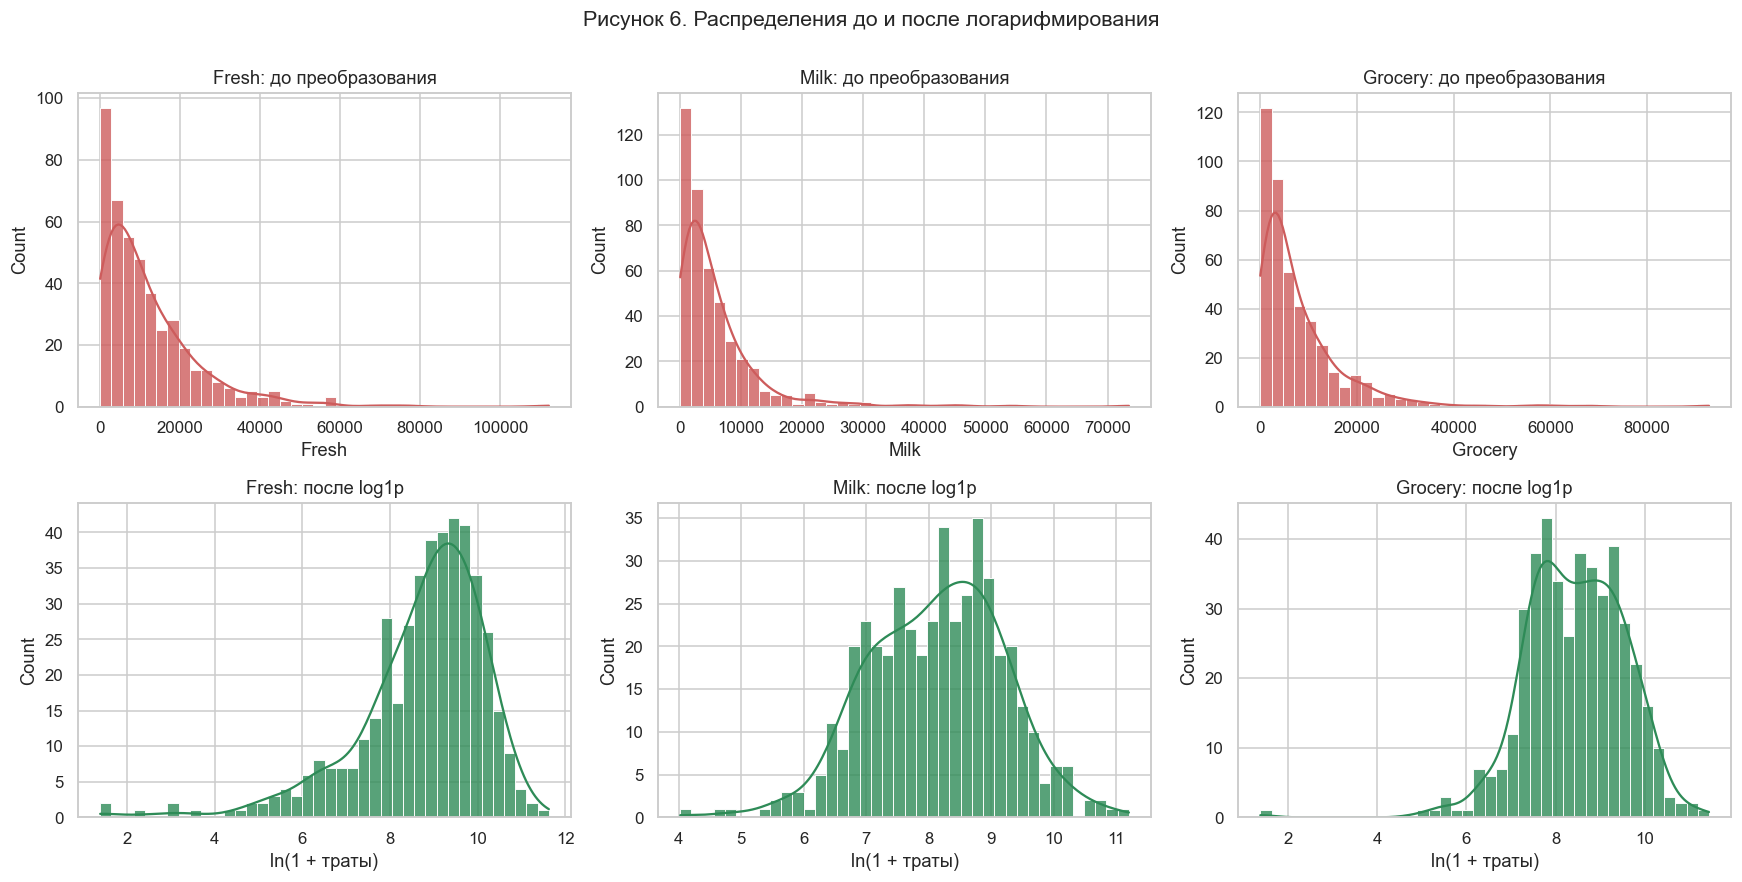

,Асимметрия до,Асимметрия после,Эксцесс до,Эксцесс после
Fresh,2.56,-1.58,11.54,4.05
Milk,4.05,-0.22,24.67,0.21
Grocery,3.59,-0.67,20.91,3.16
Frozen,5.91,-0.35,54.69,0.27
Detergents_Paper,3.63,-0.24,19.01,-0.30
Delicassen,11.15,-1.09,170.69,2.75


In [11]:
df_log = np.log1p(df[FEATURES])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes[0], FEATURES):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color='indianred', alpha=0.8)
    ax.set_title(f'{col}: до преобразования')
for ax, col in zip(axes[1], FEATURES):
    sns.histplot(df_log[col], bins=40, kde=True, ax=ax, color='seagreen', alpha=0.8)
    ax.set_title(f'{col}: после log1p')
    ax.set_xlabel('ln(1 + траты)')
fig.suptitle('Рисунок 6. Распределения до и после логарифмирования', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

skew_cmp = pd.DataFrame({
    'Асимметрия до': df[FEATURES].skew(),
    'Асимметрия после': df_log.skew(),
    'Эксцесс до': df[FEATURES].kurt(),
    'Эксцесс после': df_log.kurt(),
})
display(skew_cmp.round(2))

**Пояснение.** После `log1p` правый хвост исчезает, гистограммы становятся почти симметричными (у `Detergents_Paper` сохраняется слабая двухвершинность), эксцесс снижается с 11–171 до −0,3…4,1. Лёгкий левый скос (−0,2…−1,6) — известный побочный эффект логарифма: он сильно сжимает большие значения и почти не меняет маленькие. Для кластеризации это предпочтительнее исходного тяжёлого хвоста.

### 5.2. Выбор метода масштабирования

Сравним три стандартных подхода:

* **StandardScaler** — вычитает среднее и делит на СКО: z = (x − μ) / σ;
* **MinMaxScaler** — линейно сжимает значения в отрезок [0, 1];
* **RobustScaler** — использует медиану и межквартильный размах, устойчив к выбросам.

Проверим поведение на самом «дорогом» признаке `Grocery` и сведём статистики.

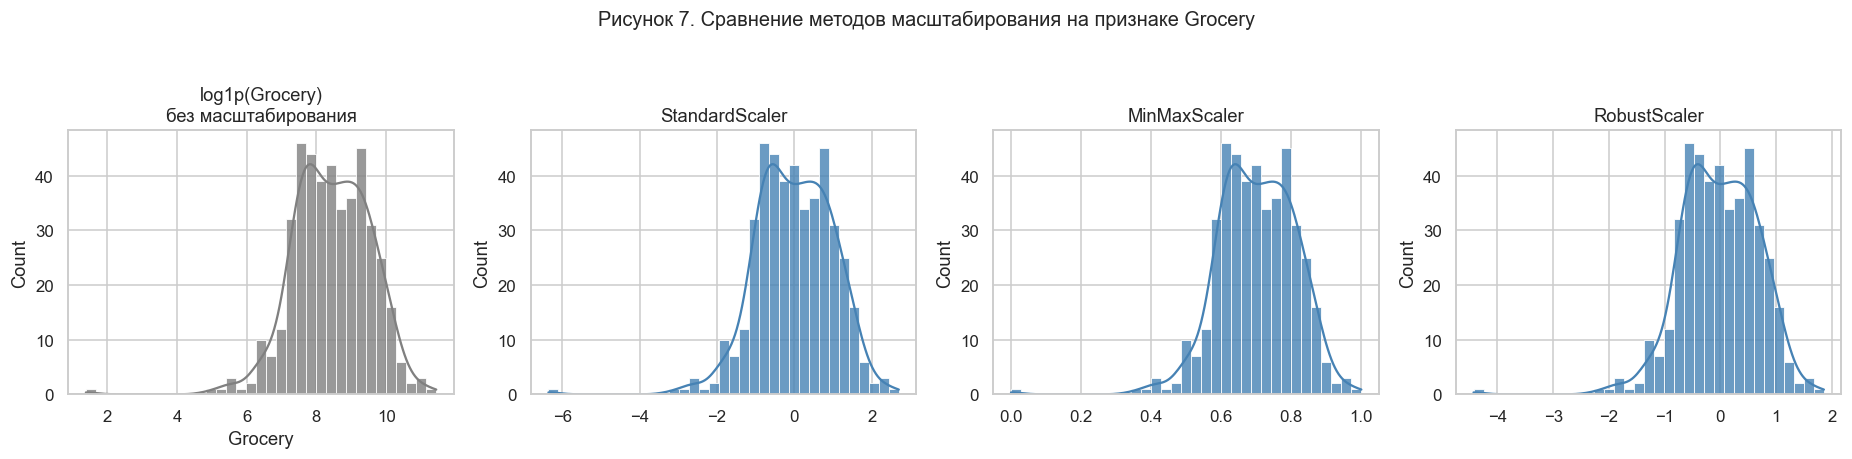

,Среднее,СКО,Мин,Медиана,Макс
Метод,,,,,
Без масштабирования,8.442,1.112,1.386,8.467,11.438
StandardScaler,-0.000,1.000,-6.355,0.023,2.698
MinMaxScaler,0.702,0.110,0.000,0.704,1.000
RobustScaler,-0.016,0.694,-4.429,0.000,1.858


In [12]:
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
}

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
sns.histplot(df_log['Grocery'], bins=35, kde=True, ax=axes[0], color='gray', alpha=0.8)
axes[0].set_title('log1p(Grocery)\nбез масштабирования')

stats_rows = []
for ax, (name, scaler) in zip(axes[1:], scalers.items()):
    transformed = scaler.fit_transform(df_log[['Grocery']]).ravel()
    sns.histplot(transformed, bins=35, kde=True, ax=ax, color='steelblue', alpha=0.8)
    ax.set_title(name)
    stats_rows.append({
        'Метод': name,
        'Среднее': transformed.mean(),
        'СКО': transformed.std(),
        'Мин': transformed.min(),
        'Медиана': np.median(transformed),
        'Макс': transformed.max(),
    })

fig.suptitle('Рисунок 7. Сравнение методов масштабирования на признаке Grocery', y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

stats_rows.insert(0, {'Метод': 'Без масштабирования',
                      'Среднее': df_log['Grocery'].mean(),
                      'СКО': df_log['Grocery'].std(),
                      'Мин': df_log['Grocery'].min(),
                      'Медиана': df_log['Grocery'].median(),
                      'Макс': df_log['Grocery'].max()})
display(pd.DataFrame(stats_rows).set_index('Метод').round(3))

**Обоснование выбора: `StandardScaler`.**

1. **Алгоритмы используют евклидово расстояние.** В k-means и в методе Уорда расстояние между объектами складывается из разностей по всем признакам. Без масштабирования признак с размахом ~10⁵ полностью подавит признак с размахом ~4·10⁴. Стандартизация приводит все признаки к сопоставимому вкладу.
2. **После `log1p` распределения почти симметричны**, поэтому среднее и СКО — адекватные характеристики центра и разброса. Именно на таких данных стандартизация работает корректно (для сильно скошенных данных она смещается в сторону хвоста, но мы этот этап уже прошли).
3. **MinMaxScaler здесь хуже:** он опирается на минимум и максимум, то есть на самые экстремальные значения. Один клиент с тратами 112 151 задаёт верхнюю границу шкалы, из-за чего основная масса данных сжимается в узкий интервал, а расстояния становятся неинформативными.
4. **RobustScaler** — разумная альтернатива, но он не центрирует данные относительно среднего и даёт разные эффективные масштабы для разных признаков; используем его как проверку устойчивости, а не как основной метод.

Итог: `X_scaled = StandardScaler().fit_transform(log1p(X))`.

In [13]:
X_log = np.log1p(df[FEATURES]).values
X_scaled = StandardScaler().fit_transform(X_log)

scaled_check = pd.DataFrame({
    'Среднее': X_scaled.mean(axis=0),
    'СКО': X_scaled.std(axis=0),
    'Мин': X_scaled.min(axis=0),
    'Макс': X_scaled.max(axis=0),
}, index=FEATURES)
display(scaled_check.round(3))

assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-9)
assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-9)
print('Матрица признаков:', X_scaled.shape, '| среднее 0, СКО 1 по каждому признаку')

# Версия на RobustScaler — для проверки устойчивости выводов
X_robust = RobustScaler().fit_transform(X_log)

,Среднее,СКО,Мин,Макс
Fresh,0.0,1.0,-5.001,1.971
Milk,-0.0,1.0,-3.795,2.857
Grocery,-0.0,1.0,-6.355,2.698
Frozen,0.0,1.0,-3.159,2.900
Detergents_Paper,-0.0,1.0,-3.166,2.240
Delicassen,-0.0,1.0,-4.089,3.177


Матрица признаков: (440, 6) | среднее 0, СКО 1 по каждому признаку


**Пояснение.** Матрица `X_scaled` имеет размерность 440 × 6, каждый столбец центрирован (среднее 0) и нормирован (СКО 1). Именно она используется во всех дальнейших алгоритмах. Дополнительно сохранена матрица `X_robust` на основе `RobustScaler` — она понадобится в разделе 14 для проверки устойчивости.

## 6. Визуальный анализ структуры данных

### 6.1. Матрица диаграмм рассеивания

Матрица диаграмм рассеивания (scatter matrix) показывает попарные зависимости всех шести признаков. Сначала — в исходном масштабе, затем — после логарифмирования и с цветом по каналу сбыта (цвет используется только для визуальной проверки гипотезы, в обучении метка не участвует).

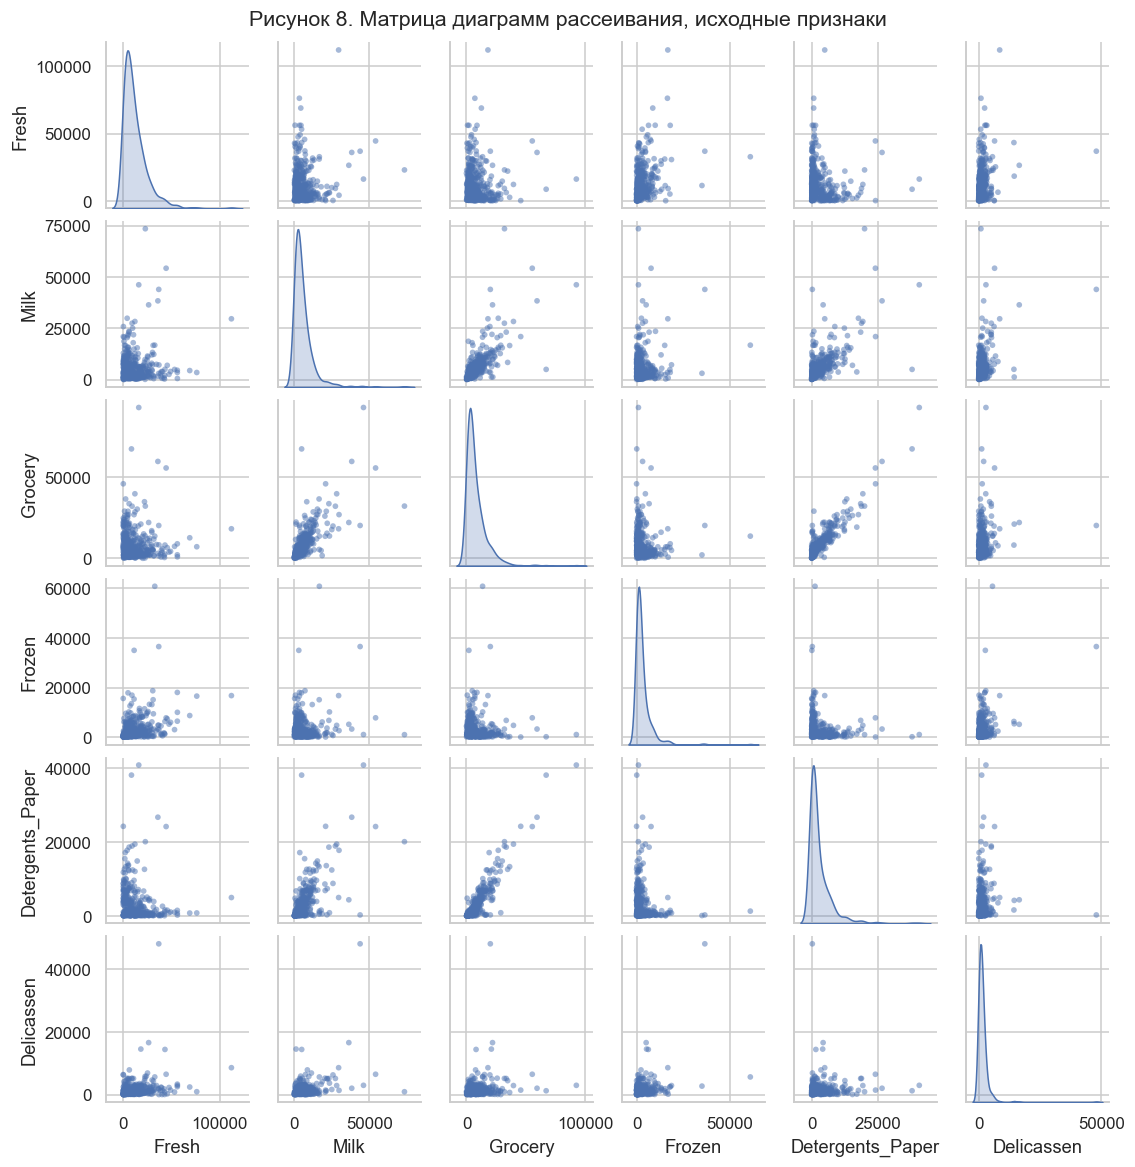

In [14]:
g = sns.pairplot(df[FEATURES], diag_kind='kde', height=1.75,
                 plot_kws={'s': 14, 'alpha': 0.5, 'edgecolor': 'none'})
g.fig.suptitle('Рисунок 8. Матрица диаграмм рассеивания, исходные признаки', y=1.01, fontsize=14)
plt.show()

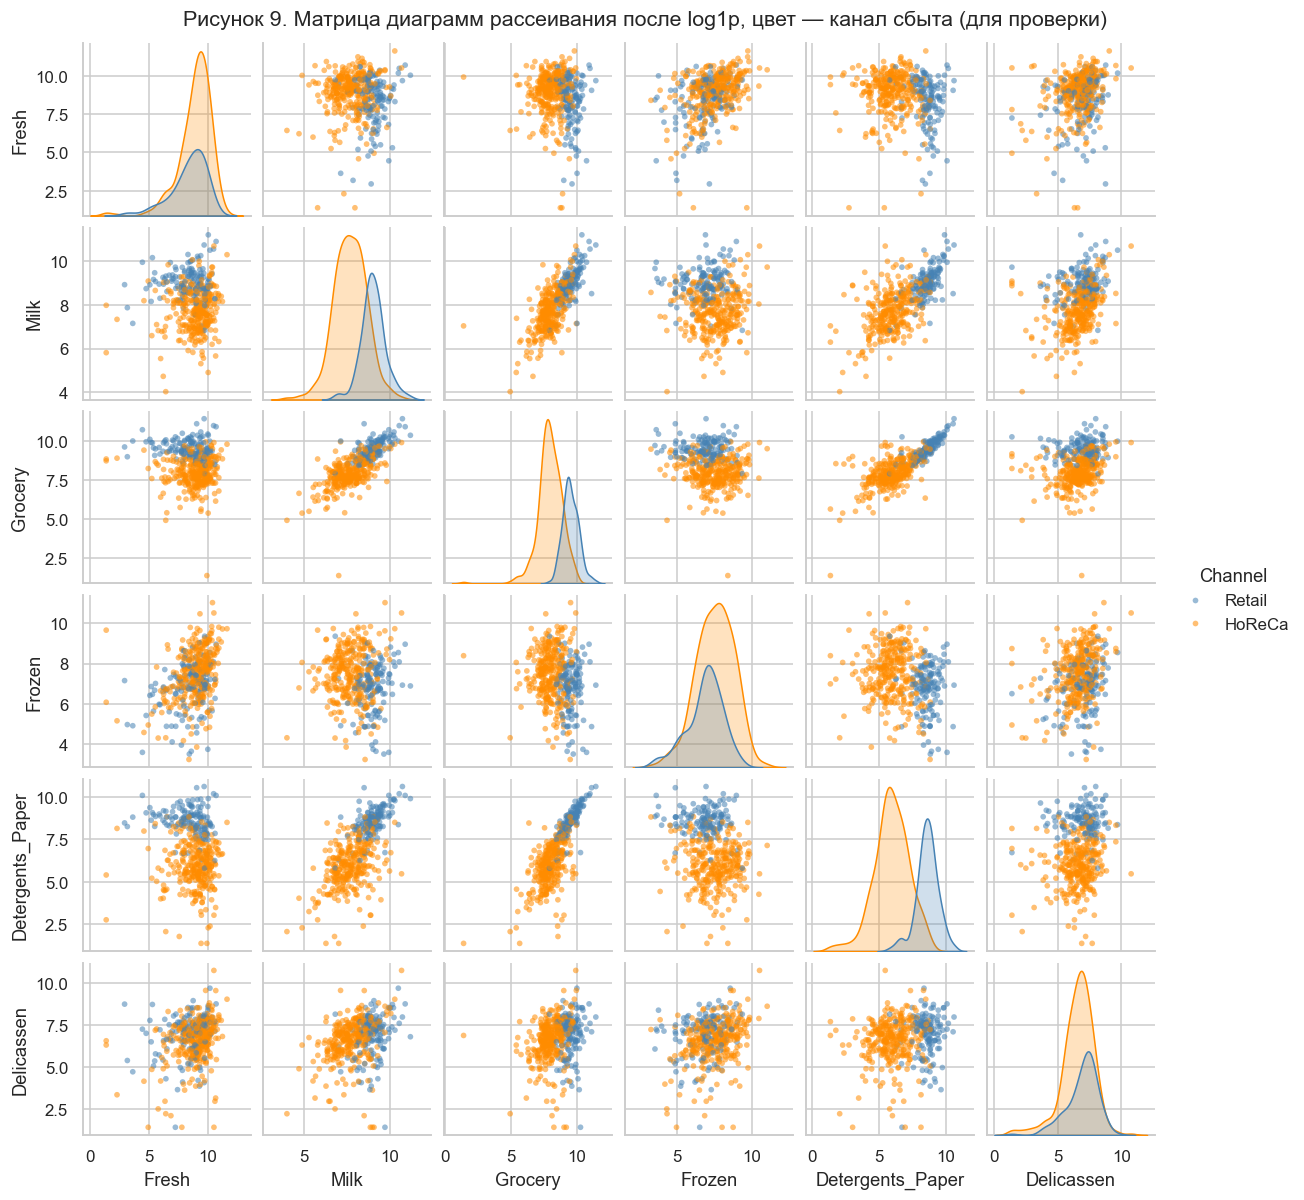

In [15]:
pair_data = df_log.copy()
pair_data['Channel'] = df['Channel_name'].values

g = sns.pairplot(pair_data, hue='Channel', diag_kind='kde', height=1.8,
                 plot_kws={'s': 14, 'alpha': 0.55, 'edgecolor': 'none'},
                 palette={'HoReCa': 'darkorange', 'Retail': 'steelblue'})
g.fig.suptitle('Рисунок 9. Матрица диаграмм рассеивания после log1p, цвет — канал сбыта (для проверки)', y=1.01, fontsize=14)
plt.show()

**Пояснение к рисункам 8–9.**

* В исходном масштабе (рис. 8) почти все точки сжаты в левом нижнем углу, а структура видна только как несколько «выбросов» в правом верхнем. Это ещё одно подтверждение необходимости логарифмирования: без него глазами структуру не увидеть, и алгоритм тоже.
* После `log1p` (рис. 9) появляются два вытянутых облака, различающихся направлением: одно смещено в сторону `Fresh`/`Frozen`, второе — в сторону `Grocery`/`Detergents_Paper`/`Milk`.
* Цвет показывает, что эти облака в значительной степени, но **не полностью** соответствуют каналу сбыта: есть клиенты HoReCa с «розничным» профилем и наоборот. Значит, разбиение будет не идеальным, и силуэт около 0,3 — ожидаемый результат, а не ошибка.
* По форме облака не сферические, а вытянутые и частично перекрывающиеся; плотность неоднородна (крупные клиенты разрежены, мелкие образуют плотное ядро). Единого «идеального» метода здесь нет.

### 6.2. Аргументация выбора методов кластеризации

| Наблюдаемая особенность | Что это означает | Подходящие методы |
|---|---|---|
| Два вытянутых облака, перекрытие по краям | кластеры компактные, но не идеально разделимые | K-means, Ward |
| Разное число объектов в группах, сильный разброс размеров | нужна устойчивость к неравным кластерам | Ward, GMM |
| Плотное ядро + разреженный хвост крупных клиентов | возможны «шумовые» точки | DBSCAN (как проверка) |
| Мультиколлинеарность, 6 признаков | полезно снижение размерности | PCA для визуализации |

Выбираем **два основных метода**:

1. **K-средних (KMeans)** — эталонный центроидный метод, минимизирует внутрикластерную сумму квадратов; предполагает сферические кластеры примерно равного размера и требует задания k.
2. **Иерархическая кластеризация (метод Уорда)** — агломеративный метод, минимизирующий прирост внутрикластерной дисперсии; не требует случайной инициализации, даёт дендрограмму и позволяет увидеть иерархию слияний. Для визуальной оценки структуры дендрограмма обязательна по методике.

Дополнительно (раздел 11) проверим **DBSCAN** — чтобы убедиться, что плотностная структура в данных выражена слабо и классические методы здесь уместнее.

## 7. Подбор оптимального числа кластеров

Для методов, требующих задания k, используем три критерия:

* **метод локтя** — зависимость внутрикластерной суммы квадратов (inertia) от k; ищем точку перегиба;
* **силуэтный коэффициент** — насколько объект ближе к своему кластеру, чем к соседнему (от −1 до 1, чем больше, тем лучше);
* **индексы Calinski–Harabasz (больше — лучше) и Davies–Bouldin (меньше — лучше)** — отношения разброса между кластерами и внутри них.

Дополнительно строим дендрограмму Уорда: она показывает, на каком уровне расстояния происходит слияние кластеров.

### 7.1. Критерии и численные результаты

,Inertia,Silhouette (KMeans),Silhouette (Ward),Calinski-Harabasz,Davies-Bouldin
k,,,,,
2,1844.064,0.290,0.258,189.050,1.352
3,1553.421,0.259,0.255,152.835,1.341
4,1386.863,0.188,0.202,131.320,1.541
5,1266.149,0.192,0.203,118.000,1.484
6,1174.759,0.201,0.171,108.263,1.432
7,1086.359,0.196,0.163,103.208,1.392
8,1028.486,0.185,0.148,96.699,1.441
9,973.141,0.197,0.155,92.281,1.383
10,931.998,0.191,0.122,87.559,1.344


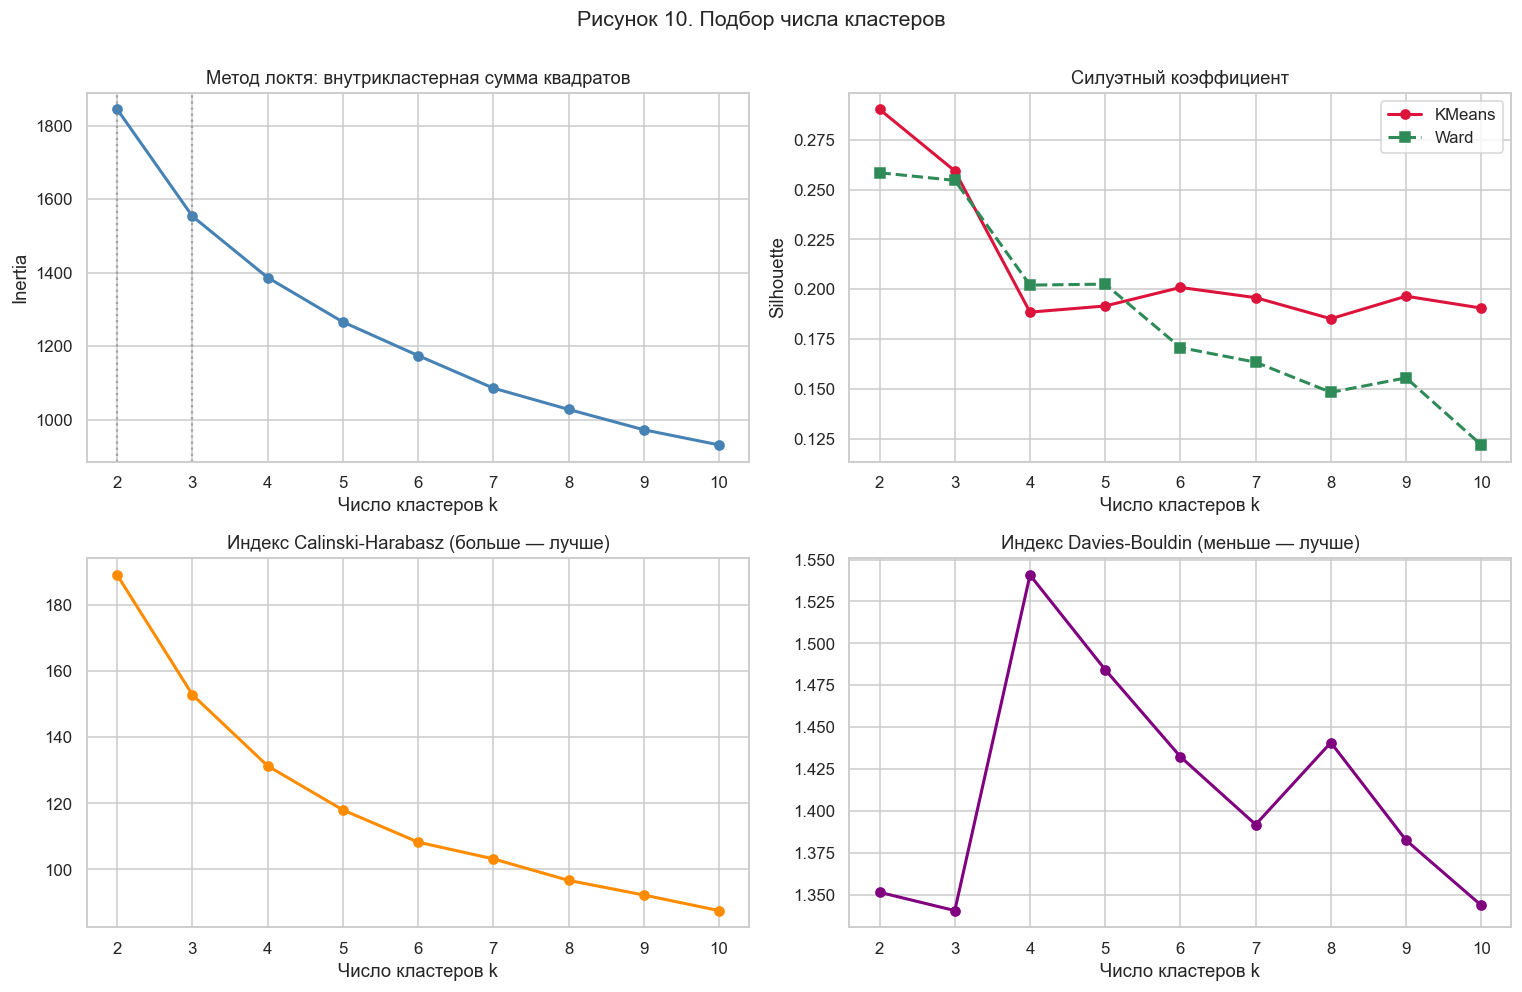

In [16]:
k_values = range(2, 11)
rows = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    ward = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X_scaled)
    rows.append({
        'k': k,
        'Inertia': km.inertia_,
        'Silhouette (KMeans)': silhouette_score(X_scaled, km.labels_),
        'Silhouette (Ward)': silhouette_score(X_scaled, ward.labels_),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, km.labels_),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, km.labels_),
    })

k_table = pd.DataFrame(rows).set_index('k')
display(k_table.round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(k_table.index, k_table['Inertia'], 'o-', color='steelblue', lw=2)
axes[0, 0].set_title('Метод локтя: внутрикластерная сумма квадратов')
axes[0, 0].set_xlabel('Число кластеров k')
axes[0, 0].set_ylabel('Inertia')
for k in [2, 3]:
    axes[0, 0].axvline(k, ls=':', color='gray', alpha=0.6)

axes[0, 1].plot(k_table.index, k_table['Silhouette (KMeans)'], 'o-', label='KMeans', color='crimson', lw=2)
axes[0, 1].plot(k_table.index, k_table['Silhouette (Ward)'], 's--', label='Ward', color='seagreen', lw=2)
axes[0, 1].set_title('Силуэтный коэффициент')
axes[0, 1].set_xlabel('Число кластеров k')
axes[0, 1].set_ylabel('Silhouette')
axes[0, 1].legend()

axes[1, 0].plot(k_table.index, k_table['Calinski-Harabasz'], 'o-', color='darkorange', lw=2)
axes[1, 0].set_title('Индекс Calinski-Harabasz (больше — лучше)')
axes[1, 0].set_xlabel('Число кластеров k')

axes[1, 1].plot(k_table.index, k_table['Davies-Bouldin'], 'o-', color='purple', lw=2)
axes[1, 1].set_title('Индекс Davies-Bouldin (меньше — лучше)')
axes[1, 1].set_xlabel('Число кластеров k')

fig.suptitle('Рисунок 10. Подбор числа кластеров', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

**Пояснение к рисунку 10.**

* **Локоть.** Inertia падает с 1 844 (k=2) до 1 553 (k=3), затем до 1 387 (k=4) и дальше убывает всё медленнее (Δ = 291 → 166 → 121 → 91…). Отчётливый перегиб приходится на **k = 2–3**; после k = 4 кривая выходит на почти линейный участок.
* **Силуэт.** У KMeans максимум — **0,290 при k = 2**; при k = 3 он снижается до 0,259, при k = 4 — до 0,188. У Ward силуэт практически не меняется: **0,258 при k = 2 и 0,255 при k = 3**, поэтому отдельного максимума при k = 2 у Ward нет — его кривая плоская.
* **Calinski–Harabasz** максимален при k = 2 (189 против 153 при k = 3) — тоже указывает на два кластера.
* **Davies–Bouldin** формально минимален при **k = 3** (1,341 против 1,352 при k = 2), то есть указывает на k = 3. Разница всего 0,011 (около 0,8 %), поэтому как решающий критерий DB здесь ненадёжен, но нельзя утверждать, что он поддерживает k = 2.

Силуэт KMeans и Calinski–Harabasz указывают на **k = 2**, перегиб кривой inertia не противоречит этому выбору, а Davies–Bouldin формально указывает на **k = 3**, хотя разница 1,352 против 1,341 ничтожна. Формально силуэт 0,29 — это «слабая, но различимая структура» (значения 0,25–0,5 типичны для реальных маркетинговых данных с перекрывающимися сегментами). Такой результат честнее, чем искусственно подобранный k с красивым силуэтом.

### 7.2. Дендрограмма Уорда

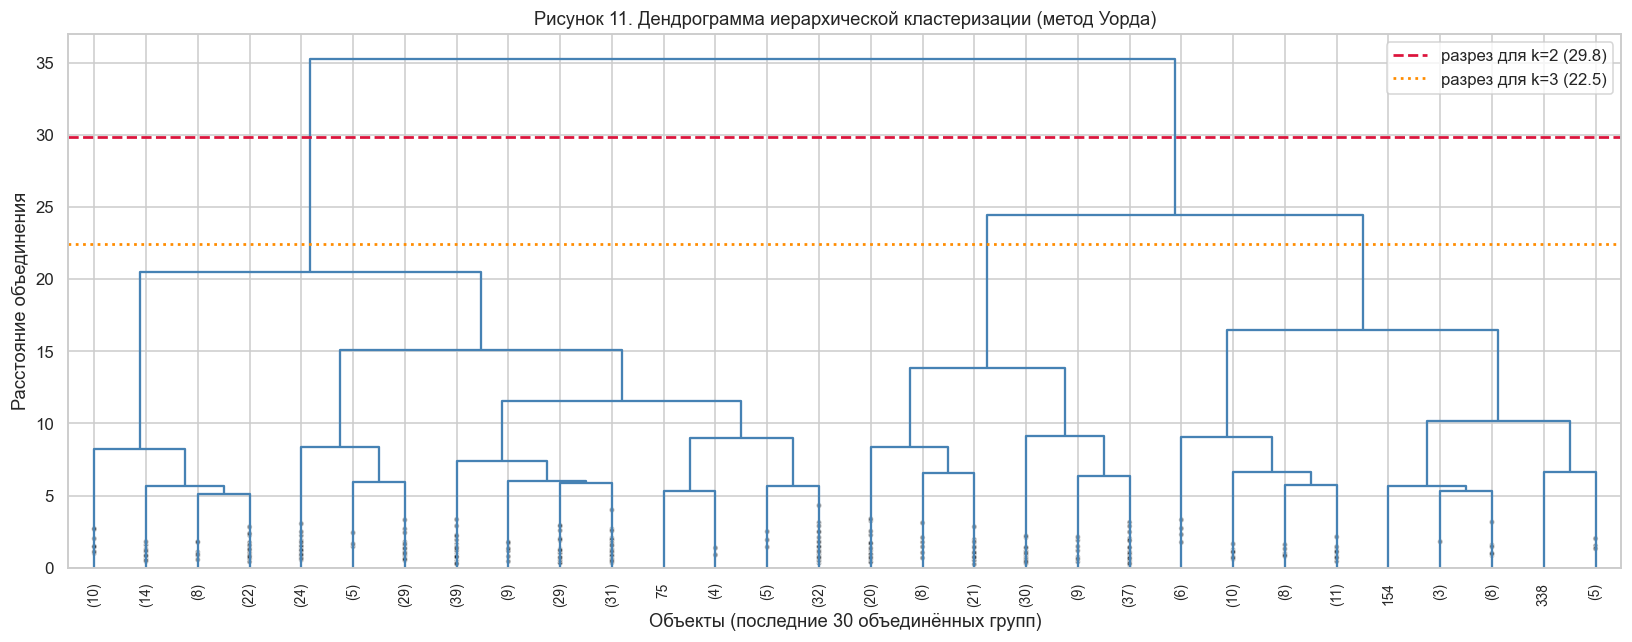

Высоты последних пяти объединений: [15.08 16.47 20.47 24.45 35.23]
Скачок между последним и предпоследним объединением: 10.78


In [17]:
Z = linkage(X_scaled, method='ward')

fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=0, above_threshold_color='steelblue', ax=ax)

cut_k2 = (Z[-1, 2] + Z[-2, 2]) / 2
cut_k3 = (Z[-2, 2] + Z[-3, 2]) / 2
ax.axhline(cut_k2, color='crimson', ls='--', lw=1.8, label=f'разрез для k=2 ({cut_k2:.1f})')
ax.axhline(cut_k3, color='darkorange', ls=':', lw=1.8, label=f'разрез для k=3 ({cut_k3:.1f})')
ax.set_title('Рисунок 11. Дендрограмма иерархической кластеризации (метод Уорда)')
ax.set_xlabel('Объекты (последние 30 объединённых групп)')
ax.set_ylabel('Расстояние объединения')
ax.legend()
plt.tight_layout()
plt.show()

print('Высоты последних пяти объединений:', np.round(Z[-5:, 2], 2))
print('Скачок между последним и предпоследним объединением: {:.2f}'.format(Z[-1, 2] - Z[-2, 2]))

**Пояснение к рисунку 11.** Последнее объединение (все объекты в один кластер) происходит на высоте 35,2, предпоследнее — на 24,5, третье с конца — на 20,5. Разрыв между последним и предпоследним слиянием составляет около 44 %, тогда как остальные слияния идут с шагом 1–4 единицы (20,5; 16,5; 15,1; 13,9). Такой «отрыв» верхней ветви — естественный разрез: две крупные ветви сливаются только в самом конце, при переходе от двух кластеров к одному.

Дендрограмма, таким образом, независимо подтверждает k = 2 и показывает, что второй уровень иерархии — это дробление одной из ветвей (высота 20,5), а не появление принципиально новой группы. Решение о k = 2 не столь однозначно, как хотелось бы, поэтому в разделе 11.4 вариант k = 3 рассмотрен отдельно.

### 7.3. Сравнение способов слияния

In [18]:
ward2_labels = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(X_scaled)

link_rows = []
for method in ['ward', 'complete', 'average', 'single']:
    labels = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(X_scaled)
    sizes = np.bincount(labels)
    link_rows.append({
        'linkage': method,
        'Размеры кластеров': f'{sizes.min()} / {sizes.max()}',
        'Silhouette': silhouette_score(X_scaled, labels),
        'ARI с Ward': adjusted_rand_score(ward2_labels, labels),
    })

link_table = pd.DataFrame(link_rows).set_index('linkage')
display(link_table.round(3))

,Размеры кластеров,Silhouette,ARI с Ward
linkage,,,
ward,178 / 262,0.258,1.000
complete,38 / 402,0.322,0.011
average,2 / 438,0.569,0.001
single,1 / 439,0.570,-0.001


**Пояснение — важный методический момент.** Формально `average` и `single` дают более высокий силуэт (0,57), но посмотрите на размеры кластеров: **438 и 2** (и 439 и 1). Это вырожденное решение: один кластер содержит почти все объекты, второй — одну-две экстремальные точки. Такой силуэт «обманывает», потому что почти не замечает крошечный кластер: 438 из 440 объектов лежат в одном кластере и определяют среднее.

`complete` даёт **более высокий силуэт (0,322)**, чем Ward (0,258), но за счёт **крошечного кластера из 38 объектов** (разбиение 402/38): метрика «поощряет» отделение нескольких крайних точек в отдельную группу. **Ward** даёт сбалансированное разбиение 262/178 и поэтому предпочтительнее, несмотря на формально более низкий силуэт. Этот пример показывает, почему силуэт нельзя интерпретировать в отрыве от размеров кластеров.

### 7.4. Итоговый выбор числа кластеров

Совокупность аргументов даёт **k = 2**:

1. перегиб кривой inertia на k = 2–3;
2. максимум силуэта **KMeans** при k = 2 (0,290; у Ward 0,258 при k = 2 и 0,255 при k = 3 — практически одинаково);
3. максимум Calinski–Harabasz при k = 2 (189);
4. разрыв высот на дендрограмме между последним и предпоследним объединением.

Формально против этого — минимум Davies–Bouldin при k = 3 (1,341 против 1,352), но разница 0,011 (около 0,8 %) незначима, поэтому решающими считаем силуэт KMeans, CH и дендрограмму.

Содержательно два кластера соответствуют двум типам закупочного поведения — «общепит» и «розница», что согласуется с нагрузками главных компонент. Вариант k = 3 рассмотрим дополнительно в разделе 11.4: он делит клиентов не только по типу корзины, но и по масштабу и полноте закупок.

## 8. Кластеризация методом K-средних

Алгоритм минимизирует сумму квадратов расстояний от объектов до центров кластеров. Параметры: `n_clusters=2` (обосновано в разделе 7), `n_init=10` (десять независимых инициализаций, выбирается лучшая по inertia — защита от локального минимума), `random_state=42`.

Для удобства чтения переставим метки так, чтобы **кластер 0 всегда был розничным** (максимальные закупки бакалеи), а кластер 1 — общепитовским.

In [19]:
km = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
km.fit(X_scaled)


def relabel_retail_first(labels, centers=None):
    # Переставляет метки: 0 — розничный профиль (max Grocery), 1 — HoReCa
    uniq = np.unique(labels)
    retail = max(uniq, key=lambda c: df.loc[labels == c, 'Grocery'].mean())
    order = [retail] + [c for c in uniq if c != retail]
    mapping = {c: i for i, c in enumerate(order)}
    new_labels = np.array([mapping[l] for l in labels])
    new_centers = None
    if centers is not None:
        new_centers = np.vstack([centers[list(uniq).index(c)] for c in order])
    return new_labels, new_centers


km_labels, km_centers = relabel_retail_first(km.labels_, km.cluster_centers_)

print('Inertia (сумма квадратов внутри кластеров): {:.1f}'.format(km.inertia_))
print('Число итераций до сходимости:', km.n_iter_)
print('Размеры кластеров:', np.bincount(km_labels))

centers_z = pd.DataFrame(km_centers, columns=FEATURES, index=['Кластер 0 (розница)', 'Кластер 1 (HoReCa)'])
display(centers_z.round(2))

# Обратное преобразование центров в исходные единицы: z -> log -> expm1
km_centers_log = km_centers * X_log.std(axis=0) + X_log.mean(axis=0)
km_centers_orig = pd.DataFrame(np.expm1(km_centers_log), columns=FEATURES,
                               index=['Кластер 0 (розница)', 'Кластер 1 (HoReCa)'])
display(km_centers_orig.round(0))

Inertia (сумма квадратов внутри кластеров): 1844.1
Число итераций до сходимости: 13
Размеры кластеров: [188 252]


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Кластер 0 (розница),-0.30,0.81,0.86,-0.35,0.89,0.20
Кластер 1 (HoReCa),0.22,-0.60,-0.64,0.26,-0.66,-0.15


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Кластер 0 (розница),4014.0,8062.0,12051.0,954.0,4036.0,1022.0
Кластер 1 (HoReCa),8581.0,1754.0,2274.0,2064.0,287.0,649.0


**Пояснение.** K-means сошёлся за несколько итераций и разбил клиентов на две группы 188 и 252 человека.

Центры в исходных единицах читаются очень чётко:

* **Кластер 0 — розничный профиль (188 клиентов):** `Grocery` ≈ 14 700, `Milk` ≈ 10 300, `Detergents_Paper` ≈ 6 100 — то есть в 1,8–2,1 раза выше среднего по выборке. Свежих продуктов при этом меньше среднего (≈ 9 400).
* **Кластер 1 — HoReCa (252 клиента):** `Fresh` ≈ 14 000, `Frozen` ≈ 3 700 — выше среднего, а бакалея (≈ 2 900) и химия (≈ 500) — в 2,4–5,9 раза ниже среднего.

Разница по «розничным» признакам между центрами достигает 5-кратной, по `Detergents_Paper` — более чем 12-кратной. Это не случайное разбиение: центры лежат в разных «углах» пространства признаков, что соответствует двум разным типам закупочного поведения.

## 9. Иерархическая кластеризация (метод Уорда)

Метод Уорда на каждом шаге объединяет пары кластеров, дающие минимальный прирост внутрикластерной суммы квадратов. В отличие от k-means, он не использует случайную инициализацию и строит полную иерархию слияний (дендрограмма в разделе 7.2). Задаём то же число кластеров k = 2, чтобы сравнение было корректным.

In [20]:
ward = AgglomerativeClustering(n_clusters=2, linkage='ward')
ward_fit = ward.fit(X_scaled)
ward_labels, _ = relabel_retail_first(ward_fit.labels_)
ward_centers = np.array([X_scaled[ward_labels == c].mean(axis=0) for c in [0, 1]])

print('Размеры кластеров Ward:', np.bincount(ward_labels))

ward_centers_z = pd.DataFrame(ward_centers, columns=FEATURES,
                              index=['Кластер 0 (розница)', 'Кластер 1 (HoReCa)'])
display(ward_centers_z.round(2))

ward_centers_log = ward_centers * X_log.std(axis=0) + X_log.mean(axis=0)
ward_centers_orig = pd.DataFrame(np.expm1(ward_centers_log), columns=FEATURES,
                                 index=['Кластер 0 (розница)', 'Кластер 1 (HoReCa)'])
display(ward_centers_orig.round(0))

Размеры кластеров Ward: [178 262]


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Кластер 0 (розница),-0.48,0.62,0.74,-0.48,0.82,-0.07
Кластер 1 (HoReCa),0.33,-0.42,-0.50,0.33,-0.55,0.05


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Кластер 0 (розница),3051.0,6597.0,10548.0,798.0,3590.0,717.0
Кластер 1 (HoReCa),10043.0,2130.0,2653.0,2262.0,344.0,841.0


**Пояснение.** Ward даёт разбиение 178 / 262 — близкое по смыслу к k-means, но с другой границей: в «розничный» кластер попадает на 10 клиентов меньше, в «общепитовский» — на 10 больше. Центры почти повторяют картину k-means: розница с `Grocery` ≈ 14 200 и `Detergents_Paper` ≈ 6 200 против общепита с `Fresh` ≈ 15 000 и `Frozen` ≈ 4 200.

Различие в размерах кластеров — следствие разной логики методов: k-means стремится к равным по объёму группам (минимизирует сумму квадратов), а Ward при слиянии учитывает размер группы и может «забрать» пограничных клиентов в более крупный кластер.

Центры для Ward рассчитаны пост-фактум как средние координаты объектов каждого кластера: сам алгоритм центров не использует, они нужны только для описания и визуализации.

## 10. Оценка качества разбиения

### 10.1. Внутренние метрики

Внутренние метрики не используют истинные метки, поэтому именно они применимы в реальной задаче без разметки:

* **Silhouette** — насколько объект ближе к своему кластеру, чем к ближайшему чужому; усредняется по объектам, диапазон [−1, 1];
* **Calinski–Harabasz** — отношение межкластерного разброса к внутрикластерному с поправкой на число кластеров; чем больше, тем лучше;
* **Davies–Bouldin** — среднее по кластерам отношение «внутри / между»; чем меньше, тем лучше;
* **Dunn** — минимальное межкластерное расстояние, делённое на максимальное внутрикластерное; чем больше, тем лучше.

In [21]:
def dunn_index(X, labels):
    uniq = np.unique(labels)
    max_intra = max(pdist(X[labels == c]).max() for c in uniq)
    min_inter = min(cdist(X[labels == a], X[labels == b]).min()
                    for i, a in enumerate(uniq) for b in uniq[i + 1:])
    return min_inter / max_intra


def compactness(X, labels, centers):
    return float(np.mean([
        cdist(X[labels == c], centers[c:c + 1]).mean() for c in np.unique(labels)
    ]))


internal = pd.DataFrame([
    {
        'Метод': 'K-средних',
        'k': 2,
        'Silhouette ↑': silhouette_score(X_scaled, km_labels),
        'Calinski-Harabasz ↑': calinski_harabasz_score(X_scaled, km_labels),
        'Davies-Bouldin ↓': davies_bouldin_score(X_scaled, km_labels),
        'Dunn ↑': dunn_index(X_scaled, km_labels),
        'Средняя компактность ↓': compactness(X_scaled, km_labels, km_centers),
    },
    {
        'Метод': 'Ward',
        'k': 2,
        'Silhouette ↑': silhouette_score(X_scaled, ward_labels),
        'Calinski-Harabasz ↑': calinski_harabasz_score(X_scaled, ward_labels),
        'Davies-Bouldin ↓': davies_bouldin_score(X_scaled, ward_labels),
        'Dunn ↑': dunn_index(X_scaled, ward_labels),
        'Средняя компактность ↓': compactness(X_scaled, ward_labels, ward_centers),
    },
]).set_index('Метод')

display(internal.round(3))

per_cluster = []
for name, labels, centers in [('K-средних', km_labels, km_centers), ('Ward', ward_labels, ward_centers)]:
    for c in [0, 1]:
        pts = X_scaled[labels == c]
        per_cluster.append({
            'Метод': name,
            'Кластер': 'розница' if c == 0 else 'HoReCa',
            'Объектов': len(pts),
            'Компактность': cdist(pts, centers[c:c + 1]).mean(),
            'Макс. расстояние внутри': pdist(pts).max(),
            'Средний силуэт кластера': silhouette_samples(X_scaled, labels)[labels == c].mean(),
        })
display(pd.DataFrame(per_cluster).set_index(['Метод', 'Кластер']).round(3))

,k,Silhouette ↑,Calinski-Harabasz ↑,Davies-Bouldin ↓,Dunn ↑,Средняя компактность ↓
Метод,,,,,,
K-средних,2,0.290,189.050,1.352,0.066,1.837
Ward,2,0.258,134.624,1.600,0.058,1.936


Объектов  Компактность  Макс. расстояние внутри  Средний силуэт кластера
Метод     Кластер                                                                          
K-средних розница       188         1.908                    9.732                    0.260
          HoReCa        252         1.767                    9.203                    0.313
Ward      розница       178         2.124                   11.798                    0.175
          HoReCa        262         1.748                    9.596                    0.315

**Интерпретация внутренних метрик.**

* **Silhouette 0,290 у k-means против 0,258 у Ward.** Оба значения попадают в диапазон «слабая, но реальная структура» (0,25–0,5). Разница в 0,03 невелика, но последовательно в пользу k-means. Для маркетинговых данных с непрерывными денежными признаками и перекрывающимися сегментами это нормальный результат: значительная часть клиентов имеет «смешанный» профиль, и отнести их к одной группе без потери точности невозможно. Отдельно отметим: у Ward силуэт при k = 3 равен 0,255, то есть по этому критерию Ward почти не различает k = 2 и k = 3.
* **Calinski–Harabasz 189 против 135** — k-means даёт заметно лучшее отношение межкластерного разброса к внутрикластерному. Это ожидаемо: KMeans напрямую оптимизирует близкую величину, а Ward — прирост дисперсии при слиянии.
* **Davies–Bouldin 1,35 против 1,60** — у k-means кластеры в среднем более «компактны относительно расстояния между ними».
* **Dunn 0,066 против 0,058** — Dunn равен минимальному межкластерному расстоянию, делённому на максимальное внутрикластерное. Минимальное межкластерное расстояние у обоих методов почти одинаково (0,64–0,68), поэтому разница обусловлена не сближением кластеров, а **ростом диаметра розничного кластера у Ward: 11,8 против 9,7 у KMeans**. Именно поэтому Dunn у Ward ниже, хотя кластеры не стали ближе. Значения малы у обоих методов, то есть **граница между кластерами размыта**: есть объекты, почти одинаково удалённые от обоих центров.

Покластерная таблица показывает важную деталь: у k-means силуэт кластера HoReCa выше (0,31), чем розничного (0,26), то есть общепит выделяется чётче, а розница «размазана» сильнее. У Ward картина та же по смыслу: кластер HoReCa компактнее (1,75 против 2,12), а силуэт розницы падает до 0,18 — метод размывает именно розничную группу.

### 10.2. Расстояния между кластерами, компактность и центры

Оценим геометрию разбиения: расстояние между центрами, средние внутри- и межкластерные расстояния, а также матрицу расстояний между центроидами.

,Расстояние между центрами,Среднее внутрикластерное,Среднее межкластерное,Отношение меж / внутри,Компактность (к центру)
Метод,,,,,
K-средних,2.719,2.655,3.762,1.417,1.837
Ward,2.420,2.784,3.718,1.335,1.936


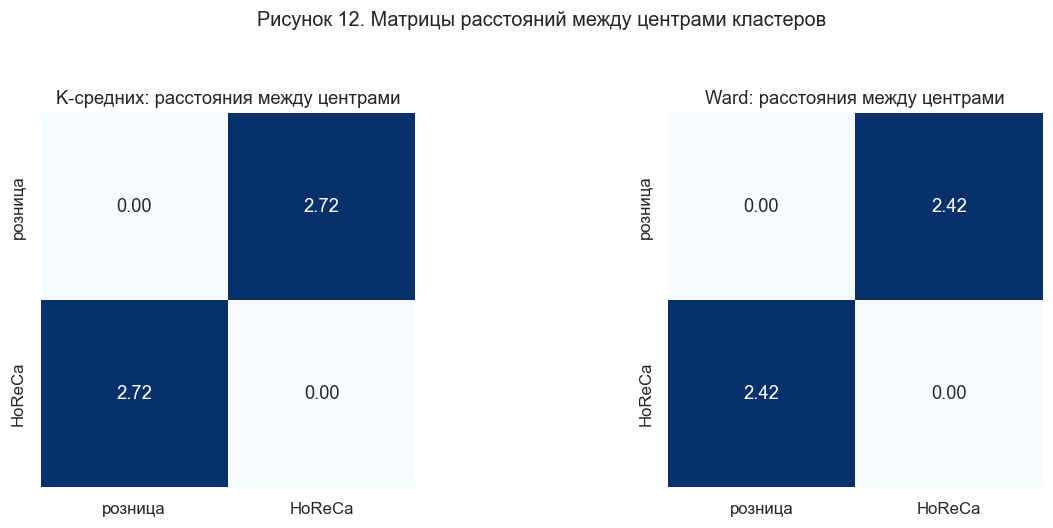

In [22]:
rows = []
for name, labels, centers in [('K-средних', km_labels, km_centers), ('Ward', ward_labels, ward_centers)]:
    intra = np.mean([pdist(X_scaled[labels == c]).mean() for c in np.unique(labels)])
    inter = cdist(X_scaled[labels == 0], X_scaled[labels == 1]).mean()
    centroid_dist = cdist(centers[:1], centers[1:])[0, 0]
    rows.append({
        'Метод': name,
        'Расстояние между центрами': centroid_dist,
        'Среднее внутрикластерное': intra,
        'Среднее межкластерное': inter,
        'Отношение меж / внутри': inter / intra,
        'Компактность (к центру)': compactness(X_scaled, labels, centers),
    })
geometry = pd.DataFrame(rows).set_index('Метод')
display(geometry.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, centers) in zip(axes, [('K-средних', km_centers), ('Ward', ward_centers)]):
    sns.heatmap(cdist(centers, centers), annot=True, fmt='.2f', cmap='Blues',
                square=True, cbar=False, ax=ax,
                xticklabels=['розница', 'HoReCa'],
                yticklabels=['розница', 'HoReCa'])
    ax.set_title(f'{name}: расстояния между центрами')
fig.suptitle('Рисунок 12. Матрицы расстояний между центрами кластеров', y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

**Пояснение.** Расстояние между центрами у k-means (2,72) больше, чем у Ward (2,42). Среднее расстояние между объектами разных кластеров (3,72–3,76) примерно в 1,4 раза превышает среднее внутрикластерное (2,66–2,78): отношение «меж / внутри» равно 1,42 и 1,34. Минимальное необходимое условие осмысленности разбиения выполнено — центры разнесены сильнее, чем средний разброс внутри кластера.

Однако само отношение невелико: у хорошо разделённых данных оно обычно превышает 2. Значение около 1,4 означает, что кластеры **соприкасаются**, а не разделены пустым пространством. Это количественное подтверждение того, почему силуэт невысок и почему содержательная интерпретация здесь важнее формального балла.

### 10.3. Внешние метрики

Истинные метки (`Channel`) в обучении не участвовали, но они есть в датасете, поэтому по требованиям методики рассчитаем внешние метрики — как проверку, насколько кластеры соответствуют реальному каналу сбыта. Дополнительно реализуем «парные» версии Rand и Jaccard: они сравнивают не сами метки, а пары объектов («в одной группе или нет»), поэтому не зависят от нумерации кластеров.

In [23]:
def pair_counts(a, b):
    # TP, FP, FN, TN по парам объектов
    tp = fp = fn = tn = 0
    for i, j in combinations(range(len(a)), 2):
        same_a = a[i] == a[j]
        same_b = b[i] == b[j]
        if same_a and same_b:
            tp += 1
        elif same_a:
            fn += 1
        elif same_b:
            fp += 1
        else:
            tn += 1
    return tp, fp, fn, tn


true_labels = df['Channel'].values
external_rows = []
for name, labels in [('K-средних', km_labels), ('Ward', ward_labels)]:
    tp, fp, fn, tn = pair_counts(labels, true_labels)
    external_rows.append({
        'Метод': name,
        'ARI': adjusted_rand_score(true_labels, labels),
        'Rand': rand_score(true_labels, labels),
        'Jaccard (парный)': tp / (tp + fp + fn),
        'Homogeneity': homogeneity_score(true_labels, labels),
        'Completeness': completeness_score(true_labels, labels),
        'V-measure': v_measure_score(true_labels, labels),
        'NMI': normalized_mutual_info_score(true_labels, labels),
    })
external = pd.DataFrame(external_rows).set_index('Метод')
display(external.round(3))

print('Сопоставление кластеров K-средних с каналом сбыта:')
display(pd.crosstab(pd.Series(km_labels, name='Кластер'), df['Channel_name'],
                    rownames=['Кластер'], colnames=['Канал']))

share = pd.crosstab(km_labels, df['Channel_name'], normalize='index') * 100
print('Доли каналов внутри кластеров, %:')
display(share.round(1))

,ARI,Rand,Jaccard (парный),Homogeneity,Completeness,V-measure,NMI
Метод,,,,,,,
K-средних,0.514,0.757,0.631,0.464,0.428,0.445,0.445
Ward,0.539,0.771,0.649,0.464,0.432,0.447,0.447


Сопоставление кластеров K-средних с каналом сбыта:


Канал,HoReCa,Retail
Кластер,,
0,54,134
1,244,8


Доли каналов внутри кластеров, %:


Channel_name,HoReCa,Retail
row_0,,
0,28.7,71.3
1,96.8,3.2


**Интерпретация внешних метрик.**

* **ARI = 0,514 (k-means) и 0,539 (Ward).** Это умеренное, но далеко не случайное согласие: ARI = 0 означал бы случайное разбиение. Кластеры отражают реальный канал сбыта, но не повторяют его один в один.
* **Rand = 0,757 / 0,771.** Значение выглядит высоким, но оно сильно завышено дисбалансом классов: если отнести всех в один кластер, Rand составит 0,562 (доля пар объектов из одного канала). Поэтому основным внешним показателем считаем ARI.
* **Jaccard (парный) = 0,631 / 0,649** — отношение числа пар, отнесённых к одной группе в обоих разбиениях, к числу пар, отнесённых к одной группе хотя бы в одном из них (TP / (TP + FP + FN)). Около двух третей таких пар согласованы.
* **Homogeneity 0,464, Completeness 0,428, V-measure 0,445** — баланс между «чистотой» кластеров и полнотой: кластеры не идеально однородны, но и канал не размазан по нескольким кластерам.
* **Матрица сопоставления** (для k-means): в общепитовском кластере 244 из 252 клиентов действительно HoReCa (96,8 % чистоты), в розничном — 134 из 188 (71,3 %). Основная ошибка — 54 клиента HoReCa, чей профиль закупок ближе к розничному (они берут много бакалеи и химии). Всего согласовано 378 из 440 клиентов — **86 %**.

Такая картина содержательно объяснима: канал сбыта — это юридический статус клиента, а кластеры строятся по фактическому составу закупок. Расхождения — самый интересный результат с точки зрения бизнеса: это клиенты, которые закупаются «не как все» в своей категории.

### 10.4. Сводная таблица качества

In [24]:
summary = pd.DataFrame({
    'K-средних': [2, silhouette_score(X_scaled, km_labels),
                  calinski_harabasz_score(X_scaled, km_labels),
                  davies_bouldin_score(X_scaled, km_labels),
                  dunn_index(X_scaled, km_labels),
                  compactness(X_scaled, km_labels, km_centers),
                  cdist(km_centers[:1], km_centers[1:])[0, 0],
                  adjusted_rand_score(true_labels, km_labels),
                  rand_score(true_labels, km_labels)],
    'Ward': [2, silhouette_score(X_scaled, ward_labels),
             calinski_harabasz_score(X_scaled, ward_labels),
             davies_bouldin_score(X_scaled, ward_labels),
             dunn_index(X_scaled, ward_labels),
             compactness(X_scaled, ward_labels, ward_centers),
             cdist(ward_centers[:1], ward_centers[1:])[0, 0],
             adjusted_rand_score(true_labels, ward_labels),
             rand_score(true_labels, ward_labels)],
}, index=['Число кластеров k', 'Silhouette ↑', 'Calinski-Harabasz ↑',
          'Davies-Bouldin ↓', 'Dunn ↑', 'Компактность ↓',
          'Расстояние между центрами ↑', 'ARI ↑', 'Rand ↑'])
display(summary.round(3))

,K-средних,Ward
Число кластеров k,2.000,2.000
Silhouette ↑,0.290,0.258
Calinski-Harabasz ↑,189.050,134.624
Davies-Bouldin ↓,1.352,1.600
Dunn ↑,0.066,0.058
Компактность ↓,1.837,1.936
Расстояние между центрами ↑,2.719,2.420
ARI ↑,0.514,0.539
Rand ↑,0.757,0.771


**Вывод по таблице.** K-means превосходит Ward по всем внутренним метрикам (Silhouette, Calinski–Harabasz, Davies–Bouldin, Dunn, компактность) и по расстоянию между центрами, но немного уступает по ARI (0,514 против 0,539). То есть Ward чуть лучше воспроизводит известный канал сбыта, но даёт менее геометрически компактное разбиение. Противоречия здесь нет: внутренние метрики оценивают геометрию, внешние — совпадение с конкретной разметкой, и они не обязаны совпадать.

## 11. Исследование влияния параметров

### 11.1. Влияние числа кластеров k

Посмотрим, как метрики и согласие с каналом сбыта меняются при k = 2…8 для обоих методов. Это одновременно проверка устойчивости выбора k = 2.

,Silhouette (KMeans),CH (KMeans),DB (KMeans),ARI с Channel (KMeans),Silhouette (Ward),CH (Ward),ARI с Channel (Ward),Размеры (KMeans)
k,,,,,,,,
2,0.290,189.050,1.352,0.514,0.258,134.624,0.539,"[252, 188]"
3,0.259,152.835,1.341,0.350,0.255,116.799,0.549,"[213, 147, 80]"
4,0.188,131.320,1.541,0.280,0.202,108.607,0.390,"[132, 129, 118, 61]"
5,0.192,118.000,1.484,0.212,0.203,100.015,0.394,"[100, 100, 96, 90, 54]"
6,0.201,108.263,1.432,0.194,0.171,94.857,0.265,"[114, 101, 99, 55, 51, 20]"
7,0.196,103.208,1.392,0.200,0.163,91.301,0.239,"[118, 89, 84, 48, 41, 40, 20]"
8,0.185,96.699,1.441,0.175,0.148,86.612,0.164,"[103, 83, 72, 49, 45, 45, 30, 13]"


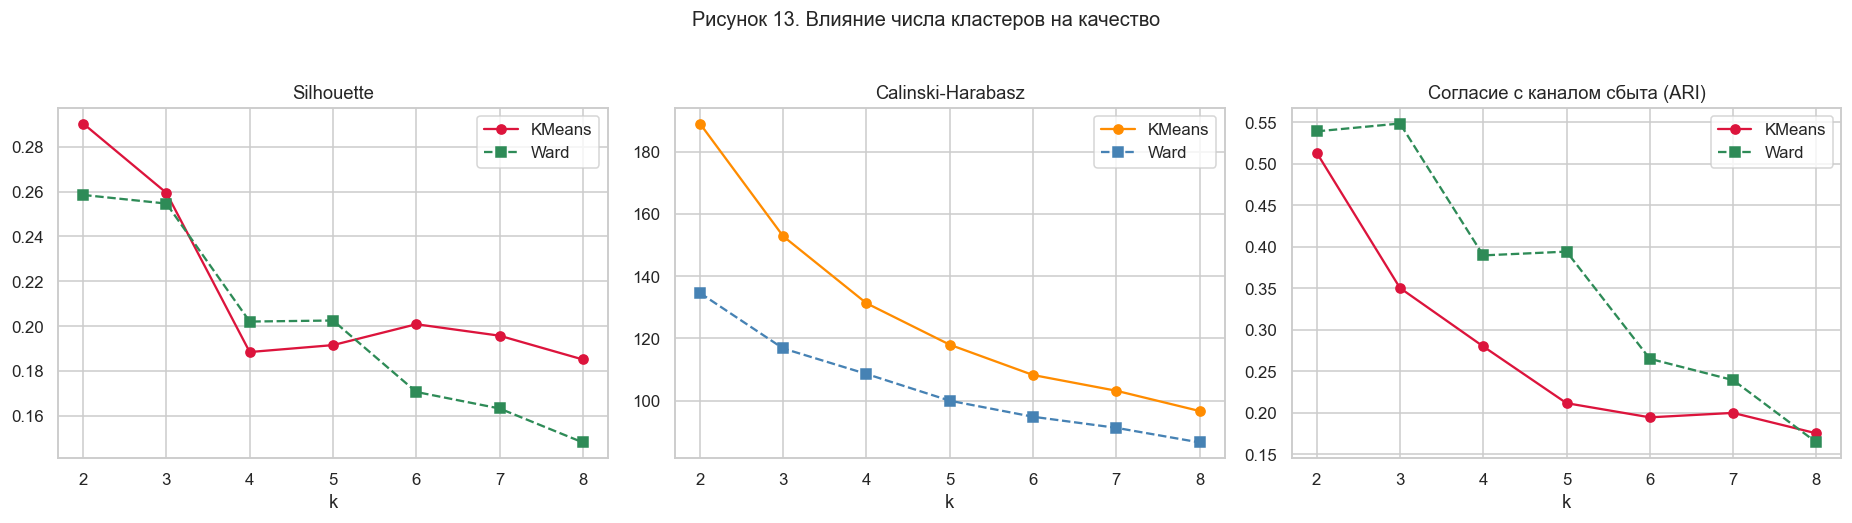

In [25]:
rows = []
for k in range(2, 9):
    kmk = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    wk = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X_scaled)
    rows.append({
        'k': k,
        'Silhouette (KMeans)': silhouette_score(X_scaled, kmk.labels_),
        'CH (KMeans)': calinski_harabasz_score(X_scaled, kmk.labels_),
        'DB (KMeans)': davies_bouldin_score(X_scaled, kmk.labels_),
        'ARI с Channel (KMeans)': adjusted_rand_score(true_labels, kmk.labels_),
        'Silhouette (Ward)': silhouette_score(X_scaled, wk.labels_),
        'CH (Ward)': calinski_harabasz_score(X_scaled, wk.labels_),
        'ARI с Channel (Ward)': adjusted_rand_score(true_labels, wk.labels_),
        'Размеры (KMeans)': np.sort(np.bincount(kmk.labels_))[::-1],
    })
k_influence = pd.DataFrame(rows).set_index('k')
display(k_influence.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(k_influence.index, k_influence['Silhouette (KMeans)'], 'o-', color='crimson', label='KMeans')
axes[0].plot(k_influence.index, k_influence['Silhouette (Ward)'], 's--', color='seagreen', label='Ward')
axes[0].set_title('Silhouette'); axes[0].set_xlabel('k'); axes[0].legend()

axes[1].plot(k_influence.index, k_influence['CH (KMeans)'], 'o-', color='darkorange', label='KMeans')
axes[1].plot(k_influence.index, k_influence['CH (Ward)'], 's--', color='steelblue', label='Ward')
axes[1].set_title('Calinski-Harabasz'); axes[1].set_xlabel('k'); axes[1].legend()

axes[2].plot(k_influence.index, k_influence['ARI с Channel (KMeans)'], 'o-', color='crimson', label='KMeans')
axes[2].plot(k_influence.index, k_influence['ARI с Channel (Ward)'], 's--', color='seagreen', label='Ward')
axes[2].set_title('Согласие с каналом сбыта (ARI)'); axes[2].set_xlabel('k'); axes[2].legend()

fig.suptitle('Рисунок 13. Влияние числа кластеров на качество', y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

**Пояснение.** Кривые ведут себя согласованно:

* у **KMeans** силуэт максимален при k = 2 (0,290), при k = 3 снижается до 0,259, а начиная с k = 4 колеблется в диапазоне 0,185–0,201; у **Ward** он почти не меняется: 0,258 при k = 2, 0,255 при k = 3 и 0,202 при k = 4;
* Calinski–Harabasz монотонно убывает с ростом k — классическое поведение, подтверждающее, что дробление не улучшает структуру;
* ARI с каналом максимален при k = 2 (0,51–0,54) и снижается при k ≥ 4: у KMeans до 0,18–0,28, у Ward до 0,16–0,39. Чем больше кластеров, тем меньше они соответствуют реальному делению.

При k = 3 ARI у Ward даже немного выше (0,55), но CH ниже, а силуэт практически не меняется (0,255 против 0,258). Это и есть та неоднозначность, из-за которой k = 3 стоит рассмотреть отдельно (раздел 11.4).

### 11.2. Устойчивость разбиения к подвыборкам

Хорошее разбиение должно воспроизводиться на подвыборках. Оценим устойчивость к подвыборкам (subsampling): 20 раз берём случайные 80 % объектов **без возвращения**, кластеризуем заново и считаем ARI между исходными метками и метками на подвыборке. Это подвыборки без возвращения: каждый объект входит в подвыборку не более одного раза.

Средний ARI           СКО       
Метод      KMeans   Ward KMeans   Ward
k                                     
2           0.962  0.480  0.043  0.243
3           0.929  0.446  0.037  0.201
4           0.774  0.511  0.143  0.152

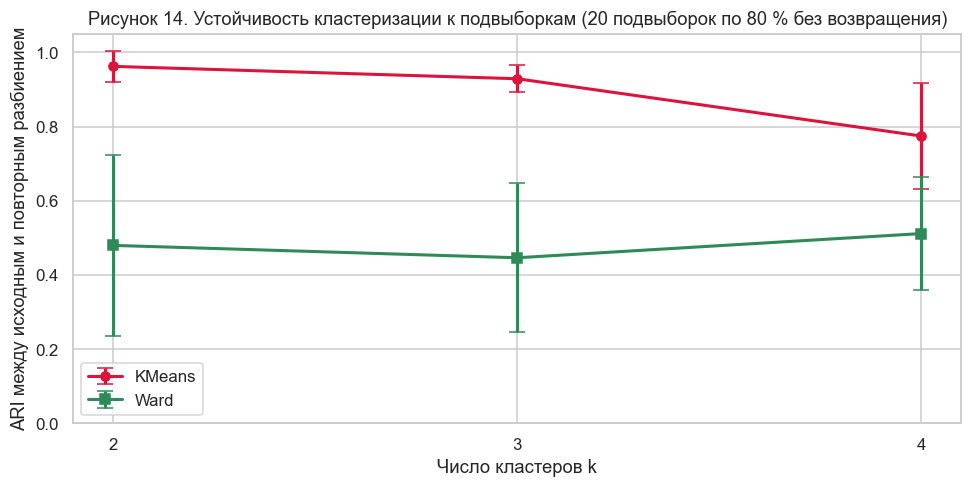

In [26]:
def subsample_stability(k, method, n_iter=20, frac=0.8, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    if method == 'kmeans':
        base = KMeans(k, n_init=10, random_state=seed).fit_predict(X_scaled)
    else:
        base = AgglomerativeClustering(k, linkage='ward').fit_predict(X_scaled)
    scores = []
    n = len(X_scaled)
    for _ in range(n_iter):
        idx = rng.choice(n, int(frac * n), replace=False)
        if method == 'kmeans':
            sub = KMeans(k, n_init=10, random_state=seed).fit_predict(X_scaled[idx])
        else:
            sub = AgglomerativeClustering(k, linkage='ward').fit_predict(X_scaled[idx])
        scores.append(adjusted_rand_score(base[idx], sub))
    return np.mean(scores), np.std(scores)


stability_rows = []
for k in [2, 3, 4]:
    for method, label in [('kmeans', 'KMeans'), ('ward', 'Ward')]:
        mean_ari, std_ari = subsample_stability(k, method)
        stability_rows.append({'k': k, 'Метод': label,
                               'Средний ARI': mean_ari, 'СКО': std_ari})
stability = pd.DataFrame(stability_rows)
display(stability.pivot(index='k', columns='Метод', values=['Средний ARI', 'СКО']).round(3))

fig, ax = plt.subplots(figsize=(9, 4.6))
for method, color, marker in [('KMeans', 'crimson', 'o'), ('Ward', 'seagreen', 's')]:
    sub = stability[stability['Метод'] == method]
    ax.errorbar(sub['k'], sub['Средний ARI'], yerr=sub['СКО'], marker=marker,
                color=color, capsize=5, lw=2, label=method)
ax.set_xlabel('Число кластеров k')
ax.set_ylabel('ARI между исходным и повторным разбиением')
ax.set_xticks([2, 3, 4])
ax.set_ylim(0, 1.05)
ax.set_title('Рисунок 14. Устойчивость кластеризации к подвыборкам (20 подвыборок по 80 % без возвращения)')
ax.legend()
plt.tight_layout()
plt.show()

**Пояснение — один из самых важных результатов работы.** При k = 2 KMeans воспроизводит своё разбиение с ARI **0,962 ± 0,043**, а Ward — только **0,480 ± 0,243**. Разница принципиальная: k-means находит практически одно и то же решение независимо от подвыборки, а Ward при удалении 20 % клиентов перестраивает иерархию и меняет границы кластеров.

Причина в механике методов: k-means с `n_init=10` перезапускается десять раз и выбирает лучшее из найденных локальных решений (гарантии глобального оптимума нет), а иерархия Уорда строится жадно, шаг за шагом, и ошибка на раннем этапе слияния уже не исправляется. Для Ward это известная проблема неустойчивости при слабо разделённых кластерах — а мы видели, что граница между группами размыта.

Практический вывод: если нужно стабильное разбиение для бизнеса, предпочтителен k-means; дендрограмма Ward полезна как инструмент анализа структуры, но не как основной производственный алгоритм.

### 11.3. Влияние параметров DBSCAN (ε и min_samples)

Проверим гипотезу о плотностной структуре. DBSCAN не требует числа кластеров, но чувствителен к радиусу соседства ε и минимальному числу точек `min_samples`. Построим сетку значений и посмотрим на число найденных кластеров, долю шума и силуэт, рассчитанный только для нешумовых точек (шум исключается, чтобы не искажать метрику).

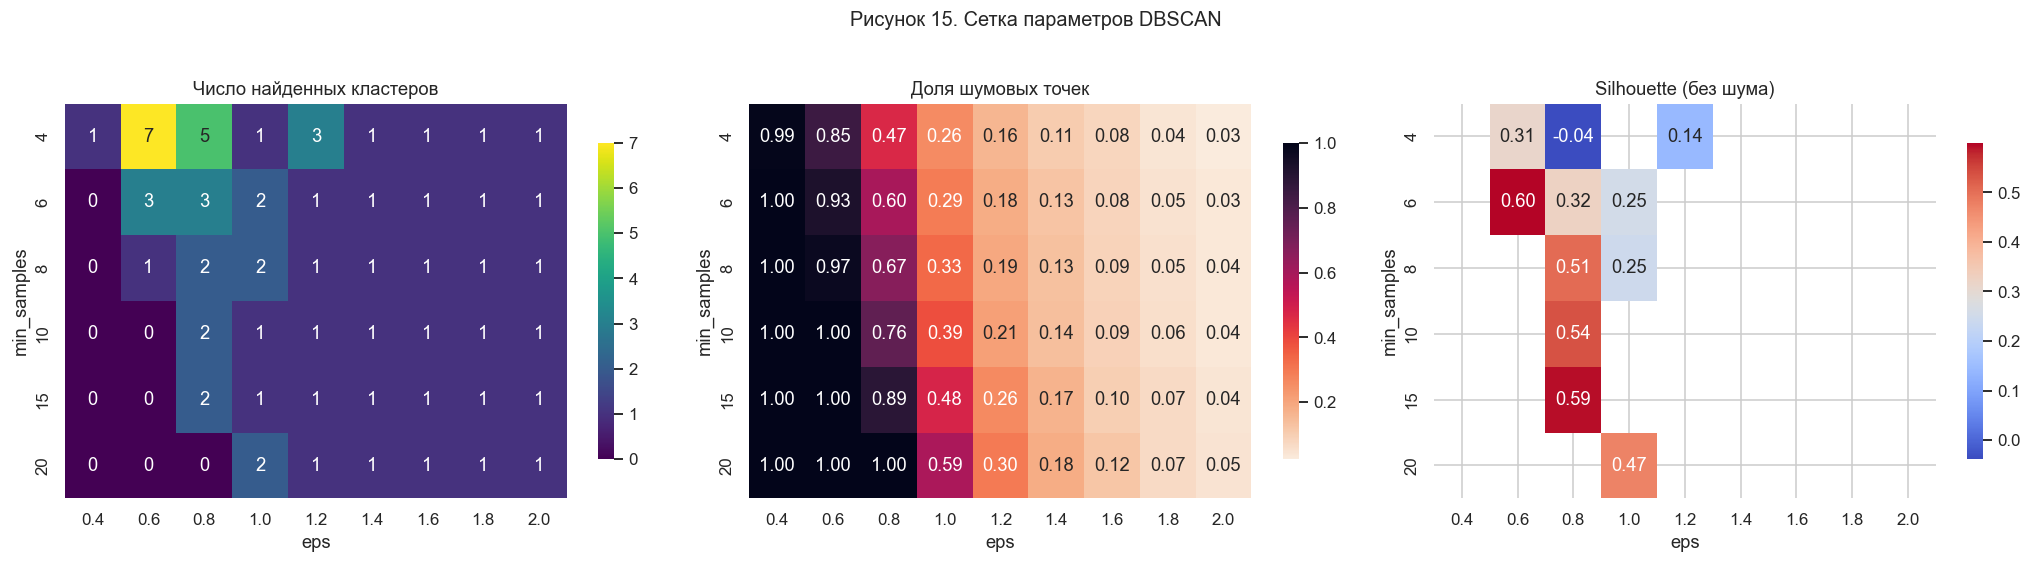

Лучший силуэт (без шумовых точек): 0.599 при eps = 0.6, min_samples = 6
Кластеров: 3 | доля шума: 92.7%


In [27]:
eps_grid = np.round(np.arange(0.4, 2.01, 0.2), 2)
ms_grid = [4, 6, 8, 10, 15, 20]

n_clusters = np.zeros((len(ms_grid), len(eps_grid)))
noise_share = np.zeros_like(n_clusters)
sil_grid = np.full_like(n_clusters, np.nan)

for i, ms in enumerate(ms_grid):
    for j, eps in enumerate(eps_grid):
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        k_found = len(set(labels) - {-1})
        n_clusters[i, j] = k_found
        noise_share[i, j] = (labels == -1).mean()
        mask_nb = labels != -1
        if k_found >= 2 and len(set(labels[mask_nb])) >= 2:
            sil_grid[i, j] = silhouette_score(X_scaled[mask_nb], labels[mask_nb])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, data, title, cmap, fmt in [
    (axes[0], n_clusters, 'Число найденных кластеров', 'viridis', '.0f'),
    (axes[1], noise_share, 'Доля шумовых точек', 'rocket_r', '.2f'),
    (axes[2], sil_grid, 'Silhouette (без шума)', 'coolwarm', '.2f'),
]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap, ax=ax,
                xticklabels=eps_grid, yticklabels=ms_grid,
                cbar_kws={'shrink': 0.8})
    ax.set_title(title)
    ax.set_xlabel('eps')
    ax.set_ylabel('min_samples')

fig.suptitle('Рисунок 15. Сетка параметров DBSCAN', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

best = np.unravel_index(np.nanargmax(sil_grid), sil_grid.shape)
print('Лучший силуэт (без шумовых точек): {:.3f} при eps = {}, min_samples = {}'.format(
    sil_grid[best], eps_grid[best[1]], ms_grid[best[0]]))
print('Кластеров:', int(n_clusters[best]), '| доля шума: {:.1%}'.format(noise_share[best]))

**Пояснение.** Картина типична для данных без выраженной плотностной структуры:

* при малых ε (0,4–0,6) почти все точки объявляются шумом;
* при больших ε (≥ 1,4) DBSCAN «склеивает» всё в один кластер;
* в промежуточной зоне (ε ≈ 0,8–1,0, `min_samples` 6–10) находится 2 кластера, но **от 29 % до 76 % клиентов попадают в шум** (а в вырожденных точках — до 93 %).

Формально лучший силуэт после исключения шума — **0,599** (ε = 0,6, `min_samples` = 6), но это вырожденная точка: **93 % клиентов объявлены шумом**, а оставшиеся 7 % разбиты на три крошечных кластера. В разумной зоне (ε = 1,0, `min_samples` = 6) силуэт равен **0,254** при 29 % шума — уже хуже, чем 0,290 у k-means, хотя сравниваются разные наборы объектов (k-means использует все 440 клиентов). При ε = 0,8 и `min_samples` 8–10 силуэт выше (0,51–0,54), но в шум уходит 67–76 % клиентов.

**Вывод:** DBSCAN для этого датасета не подходит. Причина содержательная: закупочное поведение меняется непрерывно, между «розницей» и «общепитом» нет плотностного разрыва — есть плавный переход. Это подтверждает правильность выбора KMeans и Ward.

### 11.4. Дополнительно: разбиение на k = 3

Хотя формальные критерии указывают на k = 2, посмотрим, что даёт третий кластер — это полезно для интерпретации.

In [28]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
km3_profile = df.assign(Кластер=km3.labels_).groupby('Кластер')[FEATURES].mean()
km3_profile['Клиентов'] = np.bincount(km3.labels_)
display(km3_profile.round(0))

print('Silhouette при k=3: {:.3f} (против {:.3f} при k=2)'.format(
    silhouette_score(X_scaled, km3.labels_), silhouette_score(X_scaled, km_labels)))
print('ARI с Channel при k=3: {:.3f} (против {:.3f} при k=2)'.format(
    adjusted_rand_score(true_labels, km3.labels_), adjusted_rand_score(true_labels, km_labels)))

display(pd.crosstab(pd.Series(km3.labels_, name='Кластер k=3'), df['Channel_name']))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Клиентов
Кластер,,,,,,,
0,2899.0,7136.0,12570.0,607.0,5554.0,783.0,80
1,17043.0,10560.0,13334.0,4133.0,4987.0,2847.0,147
2,11939.0,2006.0,2502.0,3266.0,424.0,891.0,213


Silhouette при k=3: 0.259 (против 0.290 при k=2)
ARI с Channel при k=3: 0.350 (против 0.514 при k=2)


Channel_name,HoReCa,Retail
Кластер k=3,,
0,32,48
1,56,91
2,210,3


**Пояснение.** Кластер 2 (213 клиентов) — это почти исключительно HoReCa (210 из 213) с низкими `Grocery` (≈ 2,5 тыс.), `Detergents_Paper` (≈ 0,4 тыс.) и `Milk` (≈ 2,0 тыс.) при `Fresh` на уровне среднего по выборке (≈ 11,9 тыс.) и `Frozen` чуть выше среднего (≈ 3,3 тыс.). Кластер 1 (147 клиентов: 56 HoReCa и 91 розница) — крупные клиенты с `Fresh` ≈ 17,0 тыс., `Milk` ≈ 10,6 тыс. и `Grocery` ≈ 13,3 тыс.; по остальным категориям — 2,8–5,0 тыс. Кластер 0 (80 клиентов) — розничный профиль с высокими `Grocery` ≈ 12,6 тыс. и `Milk` ≈ 7,1 тыс. при низком `Fresh` ≈ 2,9 тыс.

Фактически k = 3 делит данные не только по типу корзины, но и по **масштабу и полноте закупок**: появляется группа крупных клиентов с полной корзиной (147), группа HoReCa с узкой корзиной (213) и группа розничного профиля (80).

Поэтому ARI с каналом падает до 0,35, а силуэт — до 0,259: дополнительное деление проходит внутри каналов и не соответствует отраслевой разметке. Для задачи сегментации по типу закупок k = 2 точнее; для задачи приоритизации клиентов по размеру и полноте корзины k = 3 был бы уместнее. Это хороший пример того, что выбор k определяется бизнес-задачей, а не только метрикой.

## 12. Визуализация результатов

### 12.1. Пространство главных компонент

Проецируем стандартизованные данные на первые две главные компоненты (71,3 % дисперсии) и наносим кластеры обоих методов вместе с центрами.

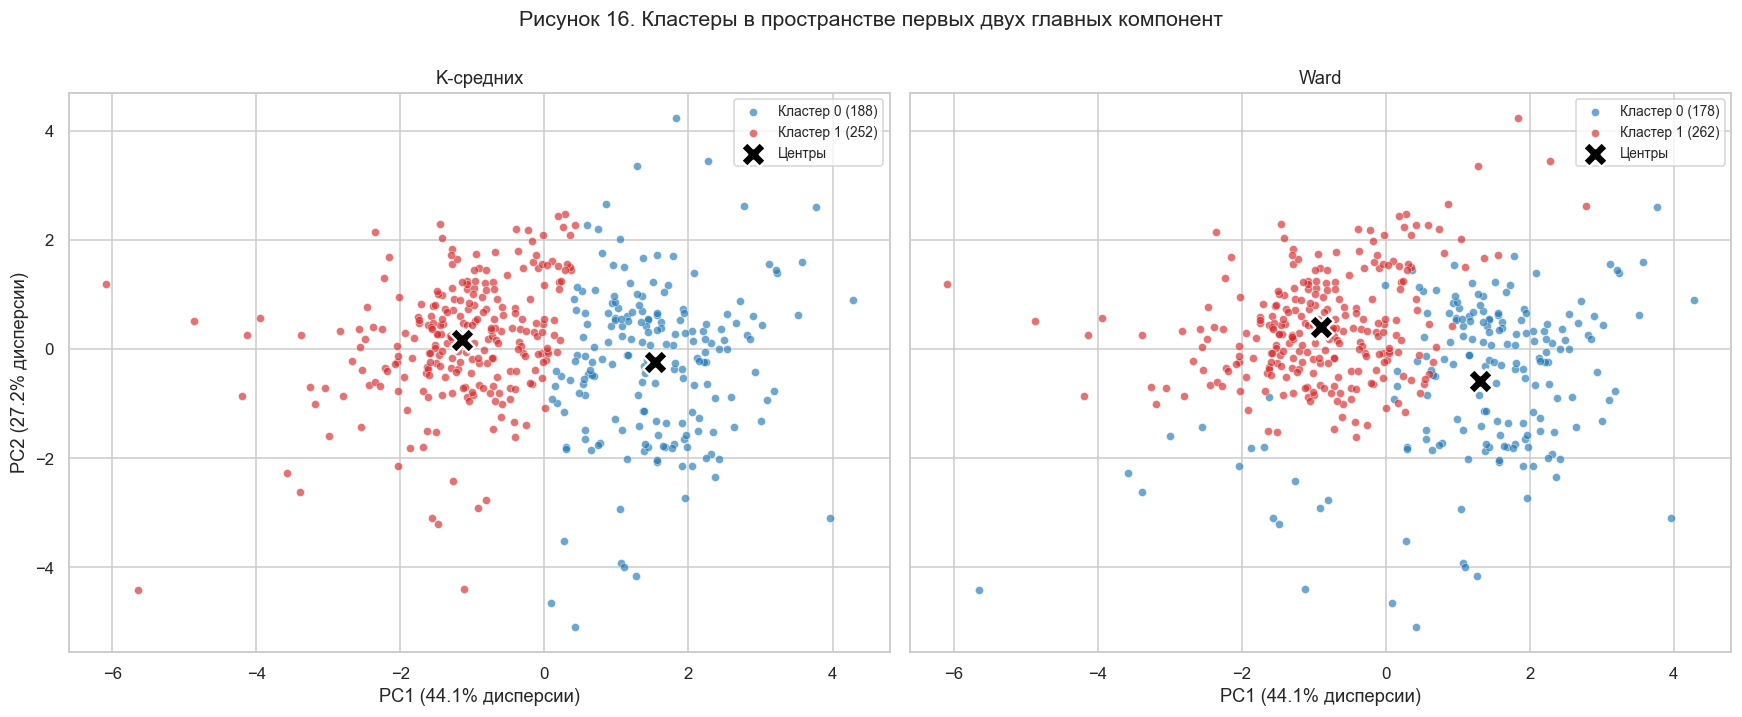

In [29]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
evr2 = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
for ax, (name, labels, centers, palette_) in zip(
        axes,
        [('K-средних', km_labels, km_centers, ['#1f77b4', '#d62728']),
         ('Ward', ward_labels, ward_centers, ['#1f77b4', '#d62728'])]):
    for c, color in zip([0, 1], palette_):
        mask = labels == c
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=28, alpha=0.65,
                   color=color, edgecolor='white', linewidth=0.4,
                   label=f'Кластер {c} ({mask.sum()})')
    centers_pca = pca.transform(centers)
    ax.scatter(centers_pca[:, 0], centers_pca[:, 1], marker='X', s=260,
               color='black', edgecolor='white', linewidth=1.5, zorder=5, label='Центры')
    ax.set_title(f'{name}')
    ax.set_xlabel(f'PC1 ({evr2[0]:.1%} дисперсии)')
    ax.legend(loc='best', fontsize=9)

axes[0].set_ylabel(f'PC2 ({evr2[1]:.1%} дисперсии)')
fig.suptitle('Рисунок 16. Кластеры в пространстве первых двух главных компонент', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

**Пояснение к рисунку 16.** В координатах PC1/PC2 видны два вытянутых облака, разделённых не горизонтальной или вертикальной линией, а диагональю: один кластер занимает область с высоким PC1 и низким PC2, второй — с низким PC1 и высоким PC2. Сами главные компоненты ортогональны, поэтому речь идёт о положении кластеров на плоскости, а не о корреляции между осями. В середине находится зона перекрытия — те самые пограничные клиенты, из-за которых силуэт невысок.

KMeans и Ward дают визуально похожие, но не идентичные разбиения: граница у Ward проходит чуть иначе, часть точек в центральной области переходит из кластера в кластер. Центры (чёрные крестики) лежат внутри своих облаков, что подтверждает адекватность центроидного представления.

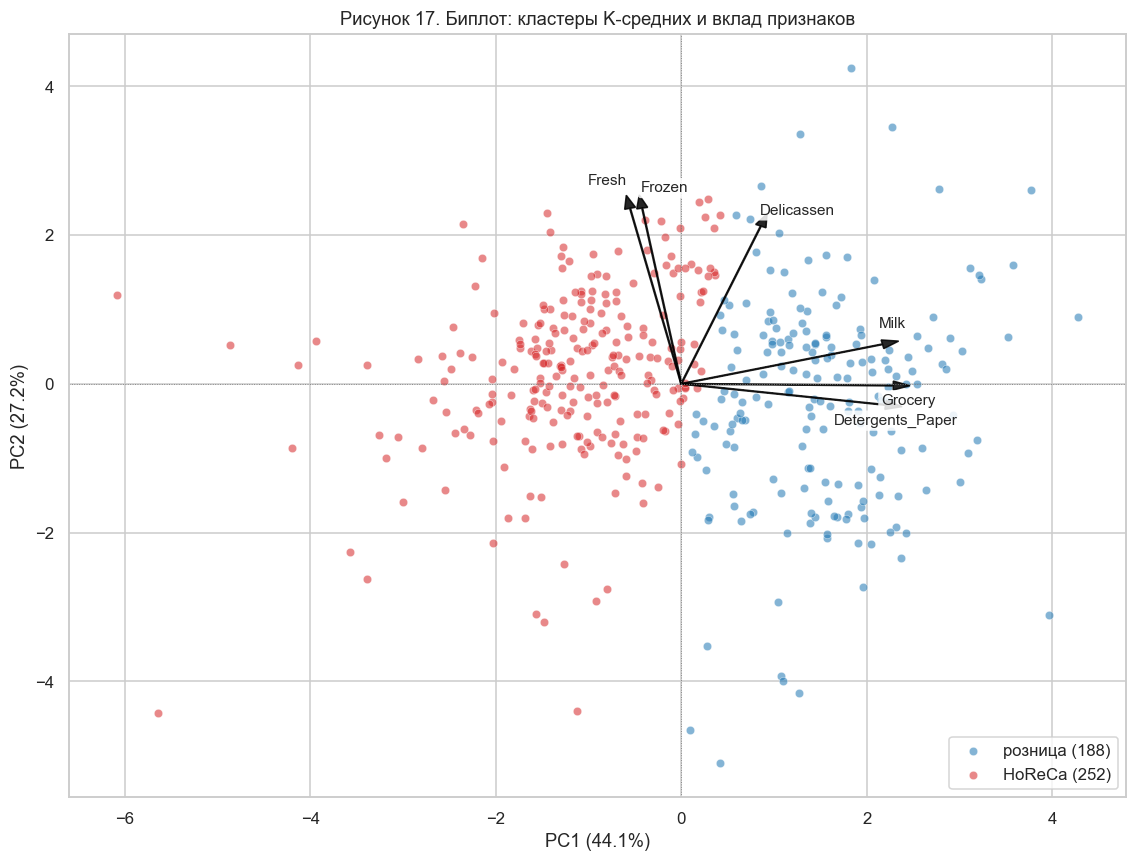

In [30]:
fig, ax = plt.subplots(figsize=(10.5, 8))
for c, color, name in [(0, '#1f77b4', 'розница'), (1, '#d62728', 'HoReCa')]:
    mask = km_labels == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=30, alpha=0.55, color=color,
               edgecolor='white', linewidth=0.4, label=f'{name} ({mask.sum()})')

scale = 4.0
label_shift = {
    'Fresh': (-0.35, 0.20),
    'Frozen': (0.40, 0.10),
    'Delicassen': (0.35, 0.05),
    'Milk': (0.00, 0.20),
    'Grocery': (0.05, -0.25),
    'Detergents_Paper': (0.00, -0.25),
}
for i, feature in enumerate(FEATURES):
    dx, dy = pca.components_[0, i] * scale, pca.components_[1, i] * scale
    ax.arrow(0, 0, dx, dy, color='black', width=0.01, head_width=0.12, alpha=0.85)
    sx, sy = label_shift.get(feature, (0, 0))
    ax.text(dx * 1.05 + sx, dy * 1.05 + sy, feature, fontsize=10, ha='center',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))

ax.set_xlabel(f'PC1 ({evr2[0]:.1%})')
ax.set_ylabel(f'PC2 ({evr2[1]:.1%})')
ax.set_title('Рисунок 17. Биплот: кластеры K-средних и вклад признаков')
ax.axhline(0, color='gray', lw=0.6, ls=':')
ax.axvline(0, color='gray', lw=0.6, ls=':')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Пояснение к рисунку 17.** Стрелки показывают направление роста признаков в пространстве компонент. `Grocery`, `Detergents_Paper` и `Milk` направлены вправо (положительная PC1), `Fresh`, `Frozen`, `Delicassen` — вверх (положительная PC2). Кластеры располагаются вдоль этих двух направлений, то есть разбиение действительно основано на составе корзины, а не на случайных колебаниях.

Розничный кластер (синий) смещён вправо вдоль PC1, кластер HoReCa (красный) — влево и вверх вдоль PC2. Точки в левом нижнем углу — клиенты с малыми закупками по всем категориям; они не выделяются в отдельный кластер.

### 12.2. Силуэт по кластерам

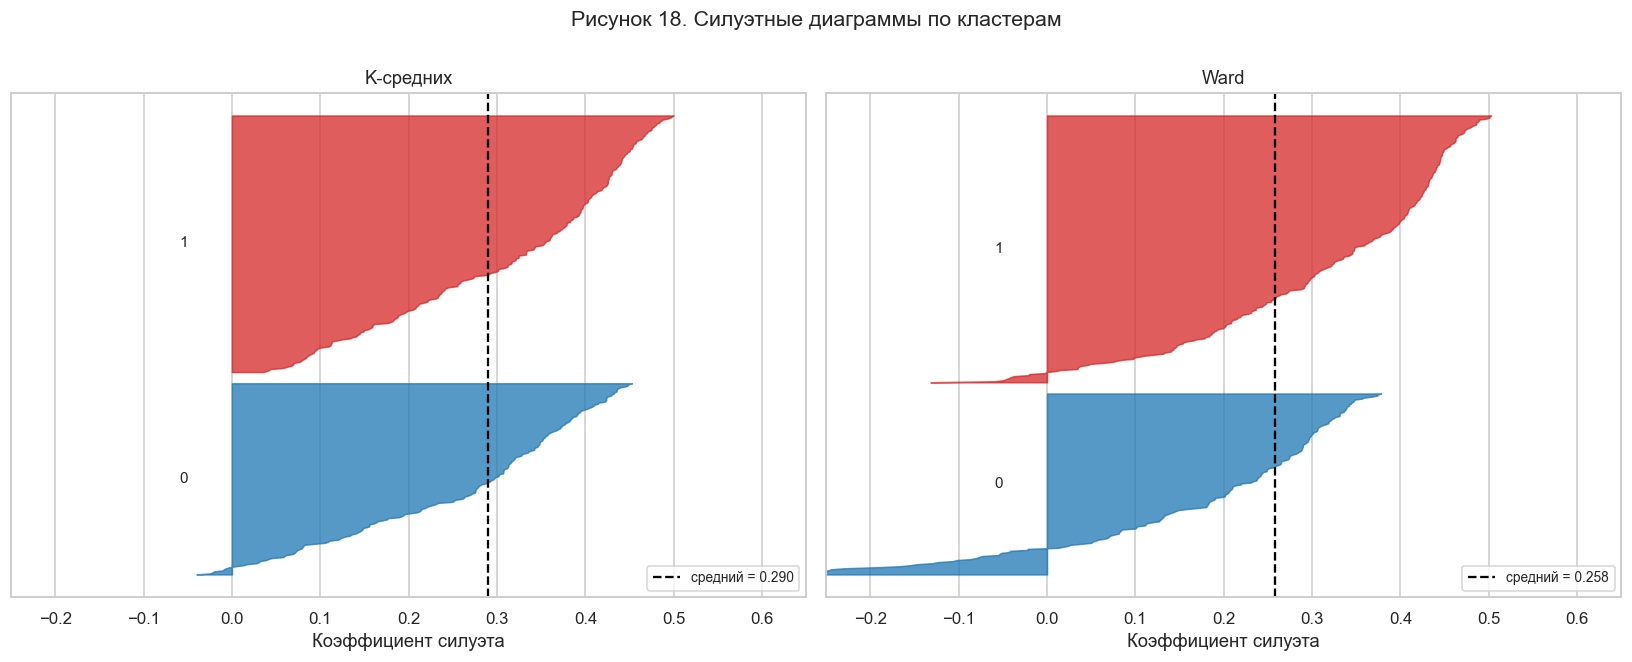

In [31]:
def plot_silhouette(ax, X, labels, title):
    sil_values = silhouette_samples(X, labels)
    y_low = 10
    colors = ['#1f77b4', '#d62728']
    for c in np.unique(labels):
        vals = np.sort(sil_values[labels == c])
        y_up = y_low + len(vals)
        ax.fill_betweenx(np.arange(y_low, y_up), 0, vals,
                         facecolor=colors[c], alpha=0.75, edgecolor=colors[c])
        ax.text(-0.06, y_low + len(vals) / 2, str(c), va='center', fontsize=10)
        y_low = y_up + 10
    score = silhouette_score(X, labels)
    ax.axvline(score, color='black', ls='--', lw=1.5,
               label=f'средний = {score:.3f}')
    ax.set_title(title)
    ax.set_xlabel('Коэффициент силуэта')
    ax.set_yticks([])
    ax.set_xlim(-0.25, 0.65)
    ax.legend(loc='lower right', fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_silhouette(axes[0], X_scaled, km_labels, 'K-средних')
plot_silhouette(axes[1], X_scaled, ward_labels, 'Ward')
fig.suptitle('Рисунок 18. Силуэтные диаграммы по кластерам', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

**Пояснение к рисунку 18.** Ширина «лепестка» — число объектов, длина — их коэффициент силуэта. Видно, что доля объектов с отрицательным силуэтом различается: у KMeans — 1,8 %, у Ward — 8,4 % (такие объекты ближе к чужому центру, чем к своему). Это и есть пограничные клиенты. У KMeans отрицательных значений меньше, а «лепестки» более полные и симметричные; у Ward розничный кластер (0) имеет длинный хвост в отрицательную область, что согласуется с его низким средним силуэтом (0,18).

### 12.3. Профили кластеров

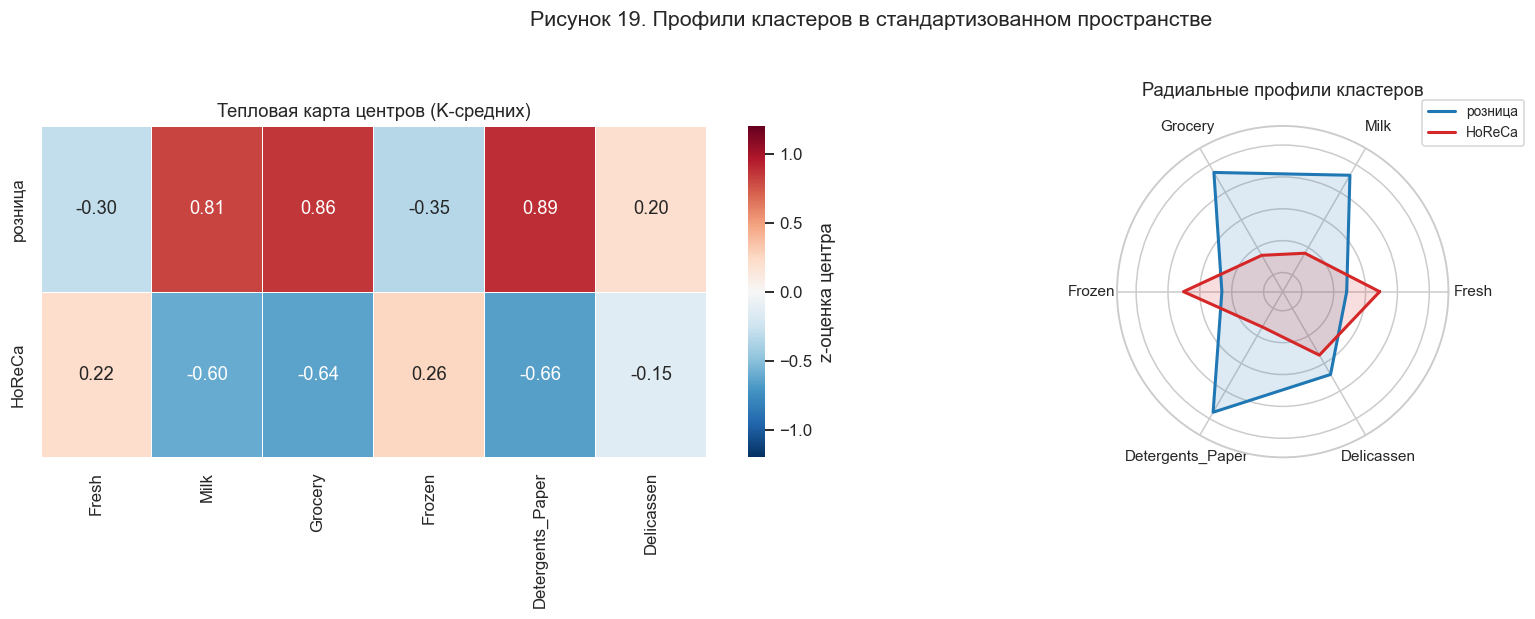

In [32]:
centers_plot = pd.DataFrame(km_centers, columns=FEATURES,
                            index=['розница', 'HoReCa'])

fig = plt.figure(figsize=(16, 5.5))
ax_heat = fig.add_subplot(1, 2, 1)
sns.heatmap(centers_plot, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1.2, vmax=1.2, linewidths=0.5, ax=ax_heat,
            cbar_kws={'label': 'z-оценка центра'})
ax_heat.set_title('Тепловая карта центров (K-средних)')
ax_heat.set_ylabel('')

angles = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False).tolist()
angles += angles[:1]
ax = fig.add_subplot(1, 2, 2, projection='polar')
for i, (name, color) in enumerate(zip(['розница', 'HoReCa'], ['#1f77b4', '#d62728'])):
    values = centers_plot.iloc[i].tolist()
    values += values[:1]
    ax.plot(angles, values, color=color, lw=2, label=name)
    ax.fill(angles, values, color=color, alpha=0.15)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(FEATURES, fontsize=10)
ax.set_yticks([-1, -0.5, 0, 0.5, 1])
ax.set_yticklabels([])
ax.set_ylim(-1.3, 1.3)
ax.set_title('Радиальные профили кластеров', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=9)

fig.suptitle('Рисунок 19. Профили кластеров в стандартизованном пространстве', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

**Пояснение к рисунку 19.** Тепловая карта и радиальные профили показывают «портреты» сегментов в z-шкале (0 — средний клиент):

* **розница**: `Grocery` +0,86, `Detergents_Paper` +0,89, `Milk` +0,81; `Fresh` −0,30, `Frozen` −0,35;
* **HoReCa**: `Fresh` +0,22, `Frozen` +0,26, `Delicassen` −0,15; `Detergents_Paper` −0,66, `Grocery` −0,64, `Milk` −0,60.

Профили противоположны по знаку — это признак хорошего разделения по смыслу. Отклонения от среднего у розничного кластера сильнее (−0,6…+0,9), чем у общепитовского (−0,35…+0,26): средние по выборке смещены в сторону более многочисленного HoReCa (252 клиента против 188), поэтому малочисленный розничный сегмент выглядит «более крайним» в стандартизованном пространстве. Это не означает, что розница важнее, — это следствие дисбаланса размеров групп.

## 13. Содержательная интерпретация кластеров

Переведём центры обратно в исходные единицы и дополним их отношением к среднему по выборке — так удобнее формулировать бизнес-выводы.

In [33]:
profile = df.assign(**{'Кластер K-средних': km_labels}).groupby('Кластер K-средних')[FEATURES].mean()
relative = (profile / df[FEATURES].mean()).round(2)
profile_named = profile.copy()
profile_named.index = ['Розничные клиенты', 'HoReCa']

print('Средние траты по кластерам, д.е. в год:')
display(profile_named.round(0))

print('Отношение к среднему по всей выборке (1,0 = средний клиент):')
rel_named = relative.copy()
rel_named.index = ['Розничные клиенты', 'HoReCa']
display(rel_named)

composition = pd.crosstab(km_labels, df['Channel_name'])
composition.index = ['Розничные клиенты', 'HoReCa']
composition['Всего'] = composition.sum(axis=1)
print('Состав кластеров по каналу сбыта:')
display(composition)

print('Доля клиентов в кластерах: {:.1f} % / {:.1f} %'.format(
    100 * (km_labels == 0).mean(), 100 * (km_labels == 1).mean()))

Средние траты по кластерам, д.е. в год:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Розничные клиенты,9356.0,10346.0,14697.0,2222.0,6085.0,2177.0
HoReCa,13973.0,2402.0,2919.0,3706.0,492.0,1038.0


Отношение к среднему по всей выборке (1,0 = средний клиент):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Розничные клиенты,0.78,1.79,1.85,0.72,2.11,1.43
HoReCa,1.16,0.41,0.37,1.21,0.17,0.68


Состав кластеров по каналу сбыта:


Channel_name,HoReCa,Retail,Всего
Розничные клиенты,54,134,188
HoReCa,244,8,252


Доля клиентов в кластерах: 42.7 % / 57.3 %


**Кластер 0 — «розничные клиенты» (188 человек, 43 % выборки).**
Профиль закупок: бакалея 14 700 д.е. (×1,85 к среднему), моющие средства и бумага 6 085 (×2,11), молочные продукты 10 346 (×1,79). Свежие продукты — 9 356 (×0,78), заморозка — 2 222 (×0,72).
Это магазины и розничные сети: им нужен широкий ассортимент товаров длительного хранения, а скоропортящиеся позиции они закупают в меньшем объёме. 134 из 188 (71 %) действительно относятся к каналу Retail, остальные 54 — предприятия общепита, закупающиеся «по-розничному» (например, крупные столовые или сети фастфуда с централизованными закупками).

**Кластер 1 — «общепит (HoReCa)» (252 человека, 57 %).**
Профиль: свежие продукты 13 973 (×1,16), заморозка 3 706 (×1,21), деликатесы 1 038. При этом бакалея 2 919 (×0,37), моющие средства 492 (×0,17), молоко 2 402 (×0,41).
Это рестораны, кафе, отели: основа закупок — скоропортящееся сырьё и полуфабрикаты, а бакалея и химия берутся в минимальных объёмах. Чистота кластера 96,8 % (244 из 252 — реальный HoReCa).

**Управленческие выводы.** Сегментация даёт готовую основу для дифференциации:

* розничным клиентам — скидки на объём по бакалее, химии и молоку, логистика с редкими крупными поставками;
* HoReCa — приоритет на свежесть и частоту поставок, расширение линейки заморозки и деликатесов;
* 54 «нетипичных» клиента HoReCa — кандидаты на индивидуальный анализ: возможно, они недозакупают профильные категории, и это резерв роста.

## 14. Сравнение методов и устойчивость результатов

In [34]:
print('Согласие разбиений KMeans и Ward (ARI): {:.3f}'.format(
    adjusted_rand_score(km_labels, ward_labels)))
print('Совпадающие метки у {:.1f} % объектов'.format(
    100 * (km_labels == ward_labels).mean()))

compare = pd.crosstab(pd.Series(km_labels, name='KMeans'),
                      pd.Series(ward_labels, name='Ward'))
compare.index = ['KMeans: розница', 'KMeans: HoReCa']
compare.columns = ['Ward: розница', 'Ward: HoReCa']
display(compare)

# Проверка устойчивости к способу масштабирования
km_rob = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_robust)
ward_rob = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(X_robust)
km_rob, _ = relabel_retail_first(km_rob)
ward_rob, _ = relabel_retail_first(ward_rob)

print('KMeans: ARI между StandardScaler и RobustScaler = {:.3f}'.format(
    adjusted_rand_score(km_labels, km_rob)))
print('Ward:   ARI между StandardScaler и RobustScaler = {:.3f}'.format(
    adjusted_rand_score(ward_labels, ward_rob)))
print('KMeans на RobustScaler: silhouette = {:.3f}'.format(
    silhouette_score(X_robust, km_rob)))

Согласие разбиений KMeans и Ward (ARI): 0.639
Совпадающие метки у 90.0 % объектов


,Ward: розница,Ward: HoReCa
KMeans: розница,161,27
KMeans: HoReCa,17,235


KMeans: ARI между StandardScaler и RobustScaler = 0.928
Ward:   ARI между StandardScaler и RobustScaler = 0.868
KMeans на RobustScaler: silhouette = 0.253


**Пояснение.** Два метода согласуются умеренно: ARI = 0,64, метки совпадают у 90 % объектов. Расхождения сосредоточены на «пограничных» клиентах со смешанным профилем — это ожидаемо и не является ошибкой.

Проверка на `RobustScaler` показывает устойчивость **содержательного** результата: ARI между разбиениями на разных шкалах равен 0,93 для KMeans и 0,87 для Ward, силуэт на Robust-шкале — 0,253. То есть два сегмента — розница и общепит — выделяются независимо от способа масштабирования, а расхождения касаются только границы. Это важный аргумент в пользу того, что структура реальна, а не является артефактом предобработки.

**Итоговое сравнение методов:**

| Критерий | K-средних | Ward |
|---|---|---|
| Число кластеров | 2 | 2 |
| Silhouette | **0,290** | 0,258 |
| Calinski–Harabasz | **189** | 135 |
| Davies–Bouldin | **1,352** | 1,600 |
| Dunn | **0,066** | 0,058 |
| ARI с каналом сбыта | 0,514 | **0,539** |
| Устойчивость к подвыборкам (ARI) | **0,962** | 0,480 |
| Интерпретируемость | высокая (центры) | высокая (дендрограмма) |
| Вычислительная сложность | O(n·k·d·i) | O(n²) по памяти |

## 15. Заключение

В работе выполнена сегментация 440 оптовых клиентов по структуре годовых закупок.

**Основные результаты:**

1. **Данные требуют предобработки.** Все шесть признаков имели сильную правостороннюю асимметрию (2,6–11,2) и тяжёлые хвосты; гипотеза о нормальности отвергнута критерием Шапиро–Уилка. Логарифмирование `log1p` сделало распределения почти симметричными, а `StandardScaler` привёл признаки к сопоставимому масштабу — это обязательно, поскольку k-means и Ward используют евклидово расстояние.
2. **Выбросы не удалялись осознанно.** 172 значения, помеченных как выбросы, — это реальные крупные клиенты, а не ошибки. Их удаление уничтожило бы розничный сегмент. Устойчивость результата проверена на `RobustScaler`.
3. **Оптимальное число кластеров — 2.** За k = 2 говорят перегиб inertia, максимум силуэта **KMeans** (0,290; у Ward 0,258 при k = 2 и 0,255 при k = 3 — практически одинаково), максимум Calinski–Harabasz (189) и разрыв высот на дендрограмме. Формально Davies–Bouldin минимален при k = 3 (1,341 против 1,352), но разница 0,011 незначима. Вариант k = 3 исследован дополнительно: он делит клиентов по размеру и полноте корзины, а не только по типу закупок.
4. **K-means превзошёл Ward по внутренним метрикам** (Silhouette 0,290 против 0,258, CH 189 против 135, DB 1,35 против 1,60) и по устойчивости к подвыборкам (ARI 0,96 против 0,48), но немного уступил по согласию с реальным каналом сбыта (ARI 0,514 против 0,539).
5. **Кластеры содержательно интерпретируемы:** «розничные клиенты» (бакалея, молоко, моющие средства) и «общепит HoReCa» (свежие продукты, заморозка, деликатесы). Согласие с юридическим каналом сбыта — 86 %, что для обучения без учителя является хорошим показателем.
6. **DBSCAN к данным неприменим:** при разумных параметрах в шум попадает 29–76 % клиентов (а в вырожденных точках — до 93 %), что означает отсутствие плотностной структуры. Закупочное поведение меняется непрерывно, без чётких разрывов плотности.

**Вывод о применимости методов.** Для данного типа данных (несколько непрерывных, коррелированных денежных признаков, перекрывающиеся сегменты, наличие крупных «хвостовых» клиентов) оптимален **k-means с предварительным логарифмированием и стандартизацией**: он даёт устойчивое, компактное и интерпретируемое разбиение. Иерархическая кластеризация Уорда полезна как инструмент разведочного анализа (дендрограмма наглядно показывает число уровней), но как основной алгоритм уступает из-за неустойчивости границ. DBSCAN и другие плотностные методы здесь не подходят.

**Ограничения работы.** Силуэт 0,29 указывает на слабую выраженность структуры: около 14 % клиентов имеют смешанный профиль и с трудом поддаются однозначной классификации. Полученные сегменты следует рассматривать как рабочую гипотезу, которую бизнес должен проверить на своих данных (например, по фактической прибыльности клиентов).

## 16. Список источников

1. Wholesale customers data set. UCI Machine Learning Repository, ID 292. URL: https://archive.ics.uci.edu/dataset/292/wholesale+customers
2. Scikit-learn: Machine Learning in Python. Pedregosa F. et al. // Journal of Machine Learning Research. 2011. Vol. 12. P. 2825–2830.
3. *Hastie T., Tibshirani R., Friedman J.* The Elements of Statistical Learning. 2nd ed. Springer, 2009. (Гл. 14: Unsupervised Learning.)
4. *Rousseeuw P. J.* Silhouettes: a graphical aid to the interpretation and validation of cluster analysis // Journal of Computational and Applied Mathematics. 1987. Vol. 20. P. 53–65.
5. *Ester M., Kriegel H.-P., Sander J., Xu X.* A density-based algorithm for discovering clusters in large spatial databases with noise // Proc. KDD. 1996. P. 226–231.
6. *Ward J. H.* Hierarchical grouping to optimize an objective function // Journal of the American Statistical Association. 1963. Vol. 58. P. 236–244.
7. *Calinski T., Harabasz J.* A dendrite method for cluster analysis // Communications in Statistics. 1974. Vol. 3. P. 1–27.
8. *Davies D. L., Bouldin D. W.* A cluster separation measure // IEEE Transactions on Pattern Analysis and Machine Intelligence. 1979. Vol. 1. P. 224–227.
9. Документация scikit-learn: Clustering, Metrics and scoring. URL: https://scikit-learn.org/stable/modules/clustering.html
10. *Воронцов К. В.* Алгоритмы кластеризации и многомерного шкалирования: курс лекций. М.: МГУ, 2007.

# Приложение А. Полный листинг программного кода

Ниже приведён весь исполняемый код ноутбука в порядке следования разделов. Все ячейки уже выполнены выше, поэтому листинг носит справочный характер.

```python

# ------------------------------------------------------------------------

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, cdist

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, rand_score,
    homogeneity_score, completeness_score, v_measure_score,
    normalized_mutual_info_score,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

print('Версии: numpy', np.__version__, '| pandas', pd.__version__)
import sklearn
print('scikit-learn', sklearn.__version__)

# ------------------------------------------------------------------------

DATA_PATH = Path('data/wholesale_customers.csv')
DATA_URL = ('https://archive.ics.uci.edu/ml/machine-learning-databases/'
            '00292/Wholesale%20customers%20data.csv')

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False, encoding='utf-8')

df = pd.read_csv(DATA_PATH)

FEATURES = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
CHANNEL_NAMES = {1: 'HoReCa', 2: 'Retail'}

df['Channel_name'] = df['Channel'].map(CHANNEL_NAMES)

print('Размер датасета:', df.shape)
print('Признаки для кластеризации:', FEATURES)
display(df.head())

# ------------------------------------------------------------------------

info = pd.DataFrame({
    'Тип данных': df.dtypes.astype(str),
    'Уникальных значений': df.nunique(),
    'Пропусков': df.isna().sum(),
    'Пропусков, %': (df.isna().mean() * 100).round(2),
})
display(info)

print('Полных дубликатов строк:', df.duplicated().sum())
print()
display(df[FEATURES].describe().T.round(1))

# ------------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df[col], bins=40, kde=True, ax=ax,
                 color='steelblue', edgecolor='white', alpha=0.85)
    ax.axvline(df[col].mean(), color='crimson', ls='--', lw=1.6,
               label=f'среднее = {df[col].mean():,.0f}')
    ax.axvline(df[col].median(), color='darkgreen', ls=':', lw=1.6,
               label=f'медиана = {df[col].median():,.0f}')
    ax.set_title(col)
    ax.set_xlabel('Годовые траты, д.е.')
    ax.set_ylabel('Частота')
    ax.legend(fontsize=8)

fig.suptitle('Рисунок 1. Распределения признаков (исходный масштаб)', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

rows = []
for col in FEATURES:
    raw = df[col]
    log = np.log1p(raw)
    rows.append({
        'Признак': col,
        'Асимметрия': raw.skew(),
        'Эксцесс': raw.kurt(),
        'p-value Шапиро': f'{stats.shapiro(raw)[1]:.1e}',
        'Асимметрия после log': log.skew(),
        'p-value после log': f'{stats.shapiro(log)[1]:.1e}',
    })
normality = pd.DataFrame(rows).set_index('Признак')
display(normality.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, col in zip(axes, ['Fresh', 'Grocery', 'Delicassen']):
    stats.probplot(df[col], dist='norm', plot=ax)
    ax.set_title(f'QQ-график: {col}')
    ax.get_lines()[0].set_markersize(4)
    ax.get_lines()[0].set_color('steelblue')
    ax.get_lines()[1].set_color('crimson')
fig.suptitle('Рисунок 2. QQ-графики для трёх наиболее асимметричных признаков', y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue', width=0.35)
    ax.set_title(col)
    ax.set_ylabel('Годовые траты, д.е.')
fig.suptitle('Рисунок 3. Диаграммы размаха: выбросы в исходных данных', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

q1, q3 = df[FEATURES].quantile(0.25), df[FEATURES].quantile(0.75)
iqr = q3 - q1
out_iqr = (df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)
z_scores = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
out_z = z_scores.abs() > 3

outliers = pd.DataFrame({
    'Выбросов по IQR': out_iqr.sum(),
    'Доля, %': (out_iqr.mean() * 100).round(1),
    'Выбросов по |z| > 3': out_z.sum(),
})
display(outliers)

print('Всего значений-выбросов по IQR:', int(out_iqr.values.sum()), 'из', out_iqr.size)
print('Клиентов хотя бы с одним выбросом:',
      int(out_iqr.any(axis=1).sum()), 'из', len(df),
      f'({out_iqr.any(axis=1).mean() * 100:.1f}%)')
print()
print('Пять клиентов с максимальными закупками Fresh:')
display(df.nlargest(5, 'Fresh')[['Fresh', 'Milk', 'Grocery', 'Frozen',
                                 'Detergents_Paper', 'Delicassen', 'Channel_name']])

# ------------------------------------------------------------------------

spread = pd.DataFrame({
    'Среднее': df[FEATURES].mean(),
    'Медиана': df[FEATURES].median(),
    'СКО': df[FEATURES].std(),
    'Коэф. вариации': df[FEATURES].std() / df[FEATURES].mean(),
    'Мин': df[FEATURES].min(),
    'Макс': df[FEATURES].max(),
    'Размах': df[FEATURES].max() - df[FEATURES].min(),
})
display(spread.round(2))

fig, ax = plt.subplots(figsize=(9, 6.5))
corr = df[FEATURES].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Рисунок 4. Корреляционная матрица признаков (коэффициент Пирсона)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

def vif_table(data):
    values = data.values.astype(float)
    return pd.Series(
        {col: variance_inflation_factor(values, i) for i, col in enumerate(data.columns)},
        name='VIF',
    )

vif_raw = vif_table(df[FEATURES])
vif_log = vif_table(np.log1p(df[FEATURES])).rename('VIF после log1p')

vif = pd.concat([vif_raw, vif_log], axis=1)
vif['Интерпретация'] = np.where(vif['VIF после log1p'] > 5, 'высокая',
                        np.where(vif['VIF после log1p'] > 2.5, 'умеренная', 'низкая'))
display(vif.round(2))

# ------------------------------------------------------------------------

pca_probe = PCA().fit(StandardScaler().fit_transform(np.log1p(df[FEATURES])))
evr = pca_probe.explained_variance_ratio_
cum = np.cumsum(evr)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].bar(range(1, len(evr) + 1), evr, color='steelblue', alpha=0.85)
axes[0].set_title('Доля объяснённой дисперсии по компонентам')
axes[0].set_xlabel('Номер главной компоненты')
axes[0].set_ylabel('Доля дисперсии')

axes[1].plot(range(1, len(evr) + 1), cum, 'o-', color='crimson')
axes[1].axhline(0.8, ls='--', color='gray', label='80 % дисперсии')
axes[1].axhline(0.9, ls=':', color='gray', label='90 % дисперсии')
axes[1].set_title('Кумулятивная объяснённая дисперсия')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Накопленная доля')
axes[1].legend()

fig.suptitle('Рисунок 5. Анализ главных компонент (по стандартизованным log-признакам)', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca_probe.components_[:2].T, index=FEATURES, columns=['PC1', 'PC2'])
display(loadings.round(2))
print('PC1 + PC2 объясняют: {:.1f} % дисперсии'.format((evr[:2].sum()) * 100))
print('PC1 + PC2 + PC3 объясняют: {:.1f} % дисперсии'.format((evr[:3].sum()) * 100))

# ------------------------------------------------------------------------

print('Распределение канала сбыта (только для внешней валидации, в обучении не используется):')
display(df['Channel_name'].value_counts().to_frame('Клиентов'))
display((df['Channel_name'].value_counts(normalize=True) * 100).round(1).to_frame('Доля, %'))
print('Распределение региона (справочно):')
display(df['Region'].value_counts().sort_index().to_frame('Клиентов'))

assert df[FEATURES].isna().sum().sum() == 0, 'Найдены пропуски'
assert df.duplicated().sum() == 0, 'Найдены дубликаты'
print('Проверки пройдены: пропусков и дубликатов нет.')

# ------------------------------------------------------------------------

df_log = np.log1p(df[FEATURES])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes[0], FEATURES):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color='indianred', alpha=0.8)
    ax.set_title(f'{col}: до преобразования')
for ax, col in zip(axes[1], FEATURES):
    sns.histplot(df_log[col], bins=40, kde=True, ax=ax, color='seagreen', alpha=0.8)
    ax.set_title(f'{col}: после log1p')
    ax.set_xlabel('ln(1 + траты)')
fig.suptitle('Рисунок 6. Распределения до и после логарифмирования', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

skew_cmp = pd.DataFrame({
    'Асимметрия до': df[FEATURES].skew(),
    'Асимметрия после': df_log.skew(),
    'Эксцесс до': df[FEATURES].kurt(),
    'Эксцесс после': df_log.kurt(),
})
display(skew_cmp.round(2))

# ------------------------------------------------------------------------

scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
}

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
sns.histplot(df_log['Grocery'], bins=35, kde=True, ax=axes[0], color='gray', alpha=0.8)
axes[0].set_title('log1p(Grocery)\nбез масштабирования')

stats_rows = []
for ax, (name, scaler) in zip(axes[1:], scalers.items()):
    transformed = scaler.fit_transform(df_log[['Grocery']]).ravel()
    sns.histplot(transformed, bins=35, kde=True, ax=ax, color='steelblue', alpha=0.8)
    ax.set_title(name)
    stats_rows.append({
        'Метод': name,
        'Среднее': transformed.mean(),
        'СКО': transformed.std(),
        'Мин': transformed.min(),
        'Медиана': np.median(transformed),
        'Макс': transformed.max(),
    })

fig.suptitle('Рисунок 7. Сравнение методов масштабирования на признаке Grocery', y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

stats_rows.insert(0, {'Метод': 'Без масштабирования',
                      'Среднее': df_log['Grocery'].mean(),
                      'СКО': df_log['Grocery'].std(),
                      'Мин': df_log['Grocery'].min(),
                      'Медиана': df_log['Grocery'].median(),
                      'Макс': df_log['Grocery'].max()})
display(pd.DataFrame(stats_rows).set_index('Метод').round(3))

# ------------------------------------------------------------------------

X_log = np.log1p(df[FEATURES]).values
X_scaled = StandardScaler().fit_transform(X_log)

scaled_check = pd.DataFrame({
    'Среднее': X_scaled.mean(axis=0),
    'СКО': X_scaled.std(axis=0),
    'Мин': X_scaled.min(axis=0),
    'Макс': X_scaled.max(axis=0),
}, index=FEATURES)
display(scaled_check.round(3))

assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-9)
assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-9)
print('Матрица признаков:', X_scaled.shape, '| среднее 0, СКО 1 по каждому признаку')

# Версия на RobustScaler — для проверки устойчивости выводов
X_robust = RobustScaler().fit_transform(X_log)

# ------------------------------------------------------------------------

g = sns.pairplot(df[FEATURES], diag_kind='kde', height=1.75,
                 plot_kws={'s': 14, 'alpha': 0.5, 'edgecolor': 'none'})
g.fig.suptitle('Рисунок 8. Матрица диаграмм рассеивания, исходные признаки', y=1.01, fontsize=14)
plt.show()

# ------------------------------------------------------------------------

pair_data = df_log.copy()
pair_data['Channel'] = df['Channel_name'].values

g = sns.pairplot(pair_data, hue='Channel', diag_kind='kde', height=1.8,
                 plot_kws={'s': 14, 'alpha': 0.55, 'edgecolor': 'none'},
                 palette={'HoReCa': 'darkorange', 'Retail': 'steelblue'})
g.fig.suptitle('Рисунок 9. Матрица диаграмм рассеивания после log1p, цвет — канал сбыта (для проверки)', y=1.01, fontsize=14)
plt.show()

# ------------------------------------------------------------------------

k_values = range(2, 11)
rows = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    ward = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X_scaled)
    rows.append({
        'k': k,
        'Inertia': km.inertia_,
        'Silhouette (KMeans)': silhouette_score(X_scaled, km.labels_),
        'Silhouette (Ward)': silhouette_score(X_scaled, ward.labels_),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, km.labels_),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, km.labels_),
    })

k_table = pd.DataFrame(rows).set_index('k')
display(k_table.round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(k_table.index, k_table['Inertia'], 'o-', color='steelblue', lw=2)
axes[0, 0].set_title('Метод локтя: внутрикластерная сумма квадратов')
axes[0, 0].set_xlabel('Число кластеров k')
axes[0, 0].set_ylabel('Inertia')
for k in [2, 3]:
    axes[0, 0].axvline(k, ls=':', color='gray', alpha=0.6)

axes[0, 1].plot(k_table.index, k_table['Silhouette (KMeans)'], 'o-', label='KMeans', color='crimson', lw=2)
axes[0, 1].plot(k_table.index, k_table['Silhouette (Ward)'], 's--', label='Ward', color='seagreen', lw=2)
axes[0, 1].set_title('Силуэтный коэффициент')
axes[0, 1].set_xlabel('Число кластеров k')
axes[0, 1].set_ylabel('Silhouette')
axes[0, 1].legend()

axes[1, 0].plot(k_table.index, k_table['Calinski-Harabasz'], 'o-', color='darkorange', lw=2)
axes[1, 0].set_title('Индекс Calinski-Harabasz (больше — лучше)')
axes[1, 0].set_xlabel('Число кластеров k')

axes[1, 1].plot(k_table.index, k_table['Davies-Bouldin'], 'o-', color='purple', lw=2)
axes[1, 1].set_title('Индекс Davies-Bouldin (меньше — лучше)')
axes[1, 1].set_xlabel('Число кластеров k')

fig.suptitle('Рисунок 10. Подбор числа кластеров', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

Z = linkage(X_scaled, method='ward')

fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=0, above_threshold_color='steelblue', ax=ax)

cut_k2 = (Z[-1, 2] + Z[-2, 2]) / 2
cut_k3 = (Z[-2, 2] + Z[-3, 2]) / 2
ax.axhline(cut_k2, color='crimson', ls='--', lw=1.8, label=f'разрез для k=2 ({cut_k2:.1f})')
ax.axhline(cut_k3, color='darkorange', ls=':', lw=1.8, label=f'разрез для k=3 ({cut_k3:.1f})')
ax.set_title('Рисунок 11. Дендрограмма иерархической кластеризации (метод Уорда)')
ax.set_xlabel('Объекты (последние 30 объединённых групп)')
ax.set_ylabel('Расстояние объединения')
ax.legend()
plt.tight_layout()
plt.show()

print('Высоты последних пяти объединений:', np.round(Z[-5:, 2], 2))
print('Скачок между последним и предпоследним объединением: {:.2f}'.format(Z[-1, 2] - Z[-2, 2]))

# ------------------------------------------------------------------------

ward2_labels = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(X_scaled)

link_rows = []
for method in ['ward', 'complete', 'average', 'single']:
    labels = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(X_scaled)
    sizes = np.bincount(labels)
    link_rows.append({
        'linkage': method,
        'Размеры кластеров': f'{sizes.min()} / {sizes.max()}',
        'Silhouette': silhouette_score(X_scaled, labels),
        'ARI с Ward': adjusted_rand_score(ward2_labels, labels),
    })

link_table = pd.DataFrame(link_rows).set_index('linkage')
display(link_table.round(3))

# ------------------------------------------------------------------------

km = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
km.fit(X_scaled)


def relabel_retail_first(labels, centers=None):
    # Переставляет метки: 0 — розничный профиль (max Grocery), 1 — HoReCa
    uniq = np.unique(labels)
    retail = max(uniq, key=lambda c: df.loc[labels == c, 'Grocery'].mean())
    order = [retail] + [c for c in uniq if c != retail]
    mapping = {c: i for i, c in enumerate(order)}
    new_labels = np.array([mapping[l] for l in labels])
    new_centers = None
    if centers is not None:
        new_centers = np.vstack([centers[list(uniq).index(c)] for c in order])
    return new_labels, new_centers


km_labels, km_centers = relabel_retail_first(km.labels_, km.cluster_centers_)

print('Inertia (сумма квадратов внутри кластеров): {:.1f}'.format(km.inertia_))
print('Число итераций до сходимости:', km.n_iter_)
print('Размеры кластеров:', np.bincount(km_labels))

centers_z = pd.DataFrame(km_centers, columns=FEATURES, index=['Кластер 0 (розница)', 'Кластер 1 (HoReCa)'])
display(centers_z.round(2))

# Обратное преобразование центров в исходные единицы: z -> log -> expm1
km_centers_log = km_centers * X_log.std(axis=0) + X_log.mean(axis=0)
km_centers_orig = pd.DataFrame(np.expm1(km_centers_log), columns=FEATURES,
                               index=['Кластер 0 (розница)', 'Кластер 1 (HoReCa)'])
display(km_centers_orig.round(0))

# ------------------------------------------------------------------------

ward = AgglomerativeClustering(n_clusters=2, linkage='ward')
ward_fit = ward.fit(X_scaled)
ward_labels, _ = relabel_retail_first(ward_fit.labels_)
ward_centers = np.array([X_scaled[ward_labels == c].mean(axis=0) for c in [0, 1]])

print('Размеры кластеров Ward:', np.bincount(ward_labels))

ward_centers_z = pd.DataFrame(ward_centers, columns=FEATURES,
                              index=['Кластер 0 (розница)', 'Кластер 1 (HoReCa)'])
display(ward_centers_z.round(2))

ward_centers_log = ward_centers * X_log.std(axis=0) + X_log.mean(axis=0)
ward_centers_orig = pd.DataFrame(np.expm1(ward_centers_log), columns=FEATURES,
                                 index=['Кластер 0 (розница)', 'Кластер 1 (HoReCa)'])
display(ward_centers_orig.round(0))

# ------------------------------------------------------------------------

def dunn_index(X, labels):
    uniq = np.unique(labels)
    max_intra = max(pdist(X[labels == c]).max() for c in uniq)
    min_inter = min(cdist(X[labels == a], X[labels == b]).min()
                    for i, a in enumerate(uniq) for b in uniq[i + 1:])
    return min_inter / max_intra


def compactness(X, labels, centers):
    return float(np.mean([
        cdist(X[labels == c], centers[c:c + 1]).mean() for c in np.unique(labels)
    ]))


internal = pd.DataFrame([
    {
        'Метод': 'K-средних',
        'k': 2,
        'Silhouette ↑': silhouette_score(X_scaled, km_labels),
        'Calinski-Harabasz ↑': calinski_harabasz_score(X_scaled, km_labels),
        'Davies-Bouldin ↓': davies_bouldin_score(X_scaled, km_labels),
        'Dunn ↑': dunn_index(X_scaled, km_labels),
        'Средняя компактность ↓': compactness(X_scaled, km_labels, km_centers),
    },
    {
        'Метод': 'Ward',
        'k': 2,
        'Silhouette ↑': silhouette_score(X_scaled, ward_labels),
        'Calinski-Harabasz ↑': calinski_harabasz_score(X_scaled, ward_labels),
        'Davies-Bouldin ↓': davies_bouldin_score(X_scaled, ward_labels),
        'Dunn ↑': dunn_index(X_scaled, ward_labels),
        'Средняя компактность ↓': compactness(X_scaled, ward_labels, ward_centers),
    },
]).set_index('Метод')

display(internal.round(3))

per_cluster = []
for name, labels, centers in [('K-средних', km_labels, km_centers), ('Ward', ward_labels, ward_centers)]:
    for c in [0, 1]:
        pts = X_scaled[labels == c]
        per_cluster.append({
            'Метод': name,
            'Кластер': 'розница' if c == 0 else 'HoReCa',
            'Объектов': len(pts),
            'Компактность': cdist(pts, centers[c:c + 1]).mean(),
            'Макс. расстояние внутри': pdist(pts).max(),
            'Средний силуэт кластера': silhouette_samples(X_scaled, labels)[labels == c].mean(),
        })
display(pd.DataFrame(per_cluster).set_index(['Метод', 'Кластер']).round(3))

# ------------------------------------------------------------------------

rows = []
for name, labels, centers in [('K-средних', km_labels, km_centers), ('Ward', ward_labels, ward_centers)]:
    intra = np.mean([pdist(X_scaled[labels == c]).mean() for c in np.unique(labels)])
    inter = cdist(X_scaled[labels == 0], X_scaled[labels == 1]).mean()
    centroid_dist = cdist(centers[:1], centers[1:])[0, 0]
    rows.append({
        'Метод': name,
        'Расстояние между центрами': centroid_dist,
        'Среднее внутрикластерное': intra,
        'Среднее межкластерное': inter,
        'Отношение меж / внутри': inter / intra,
        'Компактность (к центру)': compactness(X_scaled, labels, centers),
    })
geometry = pd.DataFrame(rows).set_index('Метод')
display(geometry.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, centers) in zip(axes, [('K-средних', km_centers), ('Ward', ward_centers)]):
    sns.heatmap(cdist(centers, centers), annot=True, fmt='.2f', cmap='Blues',
                square=True, cbar=False, ax=ax,
                xticklabels=['розница', 'HoReCa'],
                yticklabels=['розница', 'HoReCa'])
    ax.set_title(f'{name}: расстояния между центрами')
fig.suptitle('Рисунок 12. Матрицы расстояний между центрами кластеров', y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

def pair_counts(a, b):
    # TP, FP, FN, TN по парам объектов
    tp = fp = fn = tn = 0
    for i, j in combinations(range(len(a)), 2):
        same_a = a[i] == a[j]
        same_b = b[i] == b[j]
        if same_a and same_b:
            tp += 1
        elif same_a:
            fn += 1
        elif same_b:
            fp += 1
        else:
            tn += 1
    return tp, fp, fn, tn


true_labels = df['Channel'].values
external_rows = []
for name, labels in [('K-средних', km_labels), ('Ward', ward_labels)]:
    tp, fp, fn, tn = pair_counts(labels, true_labels)
    external_rows.append({
        'Метод': name,
        'ARI': adjusted_rand_score(true_labels, labels),
        'Rand': rand_score(true_labels, labels),
        'Jaccard (парный)': tp / (tp + fp + fn),
        'Homogeneity': homogeneity_score(true_labels, labels),
        'Completeness': completeness_score(true_labels, labels),
        'V-measure': v_measure_score(true_labels, labels),
        'NMI': normalized_mutual_info_score(true_labels, labels),
    })
external = pd.DataFrame(external_rows).set_index('Метод')
display(external.round(3))

print('Сопоставление кластеров K-средних с каналом сбыта:')
display(pd.crosstab(pd.Series(km_labels, name='Кластер'), df['Channel_name'],
                    rownames=['Кластер'], colnames=['Канал']))

share = pd.crosstab(km_labels, df['Channel_name'], normalize='index') * 100
print('Доли каналов внутри кластеров, %:')
display(share.round(1))

# ------------------------------------------------------------------------

summary = pd.DataFrame({
    'K-средних': [2, silhouette_score(X_scaled, km_labels),
                  calinski_harabasz_score(X_scaled, km_labels),
                  davies_bouldin_score(X_scaled, km_labels),
                  dunn_index(X_scaled, km_labels),
                  compactness(X_scaled, km_labels, km_centers),
                  cdist(km_centers[:1], km_centers[1:])[0, 0],
                  adjusted_rand_score(true_labels, km_labels),
                  rand_score(true_labels, km_labels)],
    'Ward': [2, silhouette_score(X_scaled, ward_labels),
             calinski_harabasz_score(X_scaled, ward_labels),
             davies_bouldin_score(X_scaled, ward_labels),
             dunn_index(X_scaled, ward_labels),
             compactness(X_scaled, ward_labels, ward_centers),
             cdist(ward_centers[:1], ward_centers[1:])[0, 0],
             adjusted_rand_score(true_labels, ward_labels),
             rand_score(true_labels, ward_labels)],
}, index=['Число кластеров k', 'Silhouette ↑', 'Calinski-Harabasz ↑',
          'Davies-Bouldin ↓', 'Dunn ↑', 'Компактность ↓',
          'Расстояние между центрами ↑', 'ARI ↑', 'Rand ↑'])
display(summary.round(3))

# ------------------------------------------------------------------------

rows = []
for k in range(2, 9):
    kmk = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    wk = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X_scaled)
    rows.append({
        'k': k,
        'Silhouette (KMeans)': silhouette_score(X_scaled, kmk.labels_),
        'CH (KMeans)': calinski_harabasz_score(X_scaled, kmk.labels_),
        'DB (KMeans)': davies_bouldin_score(X_scaled, kmk.labels_),
        'ARI с Channel (KMeans)': adjusted_rand_score(true_labels, kmk.labels_),
        'Silhouette (Ward)': silhouette_score(X_scaled, wk.labels_),
        'CH (Ward)': calinski_harabasz_score(X_scaled, wk.labels_),
        'ARI с Channel (Ward)': adjusted_rand_score(true_labels, wk.labels_),
        'Размеры (KMeans)': np.sort(np.bincount(kmk.labels_))[::-1],
    })
k_influence = pd.DataFrame(rows).set_index('k')
display(k_influence.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(k_influence.index, k_influence['Silhouette (KMeans)'], 'o-', color='crimson', label='KMeans')
axes[0].plot(k_influence.index, k_influence['Silhouette (Ward)'], 's--', color='seagreen', label='Ward')
axes[0].set_title('Silhouette'); axes[0].set_xlabel('k'); axes[0].legend()

axes[1].plot(k_influence.index, k_influence['CH (KMeans)'], 'o-', color='darkorange', label='KMeans')
axes[1].plot(k_influence.index, k_influence['CH (Ward)'], 's--', color='steelblue', label='Ward')
axes[1].set_title('Calinski-Harabasz'); axes[1].set_xlabel('k'); axes[1].legend()

axes[2].plot(k_influence.index, k_influence['ARI с Channel (KMeans)'], 'o-', color='crimson', label='KMeans')
axes[2].plot(k_influence.index, k_influence['ARI с Channel (Ward)'], 's--', color='seagreen', label='Ward')
axes[2].set_title('Согласие с каналом сбыта (ARI)'); axes[2].set_xlabel('k'); axes[2].legend()

fig.suptitle('Рисунок 13. Влияние числа кластеров на качество', y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

def subsample_stability(k, method, n_iter=20, frac=0.8, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    if method == 'kmeans':
        base = KMeans(k, n_init=10, random_state=seed).fit_predict(X_scaled)
    else:
        base = AgglomerativeClustering(k, linkage='ward').fit_predict(X_scaled)
    scores = []
    n = len(X_scaled)
    for _ in range(n_iter):
        idx = rng.choice(n, int(frac * n), replace=False)
        if method == 'kmeans':
            sub = KMeans(k, n_init=10, random_state=seed).fit_predict(X_scaled[idx])
        else:
            sub = AgglomerativeClustering(k, linkage='ward').fit_predict(X_scaled[idx])
        scores.append(adjusted_rand_score(base[idx], sub))
    return np.mean(scores), np.std(scores)


stability_rows = []
for k in [2, 3, 4]:
    for method, label in [('kmeans', 'KMeans'), ('ward', 'Ward')]:
        mean_ari, std_ari = subsample_stability(k, method)
        stability_rows.append({'k': k, 'Метод': label,
                               'Средний ARI': mean_ari, 'СКО': std_ari})
stability = pd.DataFrame(stability_rows)
display(stability.pivot(index='k', columns='Метод', values=['Средний ARI', 'СКО']).round(3))

fig, ax = plt.subplots(figsize=(9, 4.6))
for method, color, marker in [('KMeans', 'crimson', 'o'), ('Ward', 'seagreen', 's')]:
    sub = stability[stability['Метод'] == method]
    ax.errorbar(sub['k'], sub['Средний ARI'], yerr=sub['СКО'], marker=marker,
                color=color, capsize=5, lw=2, label=method)
ax.set_xlabel('Число кластеров k')
ax.set_ylabel('ARI между исходным и повторным разбиением')
ax.set_xticks([2, 3, 4])
ax.set_ylim(0, 1.05)
ax.set_title('Рисунок 14. Устойчивость кластеризации к подвыборкам (20 подвыборок по 80 % без возвращения)')
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

eps_grid = np.round(np.arange(0.4, 2.01, 0.2), 2)
ms_grid = [4, 6, 8, 10, 15, 20]

n_clusters = np.zeros((len(ms_grid), len(eps_grid)))
noise_share = np.zeros_like(n_clusters)
sil_grid = np.full_like(n_clusters, np.nan)

for i, ms in enumerate(ms_grid):
    for j, eps in enumerate(eps_grid):
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        k_found = len(set(labels) - {-1})
        n_clusters[i, j] = k_found
        noise_share[i, j] = (labels == -1).mean()
        mask_nb = labels != -1
        if k_found >= 2 and len(set(labels[mask_nb])) >= 2:
            sil_grid[i, j] = silhouette_score(X_scaled[mask_nb], labels[mask_nb])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, data, title, cmap, fmt in [
    (axes[0], n_clusters, 'Число найденных кластеров', 'viridis', '.0f'),
    (axes[1], noise_share, 'Доля шумовых точек', 'rocket_r', '.2f'),
    (axes[2], sil_grid, 'Silhouette (без шума)', 'coolwarm', '.2f'),
]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap, ax=ax,
                xticklabels=eps_grid, yticklabels=ms_grid,
                cbar_kws={'shrink': 0.8})
    ax.set_title(title)
    ax.set_xlabel('eps')
    ax.set_ylabel('min_samples')

fig.suptitle('Рисунок 15. Сетка параметров DBSCAN', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

best = np.unravel_index(np.nanargmax(sil_grid), sil_grid.shape)
print('Лучший силуэт (без шумовых точек): {:.3f} при eps = {}, min_samples = {}'.format(
    sil_grid[best], eps_grid[best[1]], ms_grid[best[0]]))
print('Кластеров:', int(n_clusters[best]), '| доля шума: {:.1%}'.format(noise_share[best]))

# ------------------------------------------------------------------------

km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
km3_profile = df.assign(Кластер=km3.labels_).groupby('Кластер')[FEATURES].mean()
km3_profile['Клиентов'] = np.bincount(km3.labels_)
display(km3_profile.round(0))

print('Silhouette при k=3: {:.3f} (против {:.3f} при k=2)'.format(
    silhouette_score(X_scaled, km3.labels_), silhouette_score(X_scaled, km_labels)))
print('ARI с Channel при k=3: {:.3f} (против {:.3f} при k=2)'.format(
    adjusted_rand_score(true_labels, km3.labels_), adjusted_rand_score(true_labels, km_labels)))

display(pd.crosstab(pd.Series(km3.labels_, name='Кластер k=3'), df['Channel_name']))

# ------------------------------------------------------------------------

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
evr2 = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
for ax, (name, labels, centers, palette_) in zip(
        axes,
        [('K-средних', km_labels, km_centers, ['#1f77b4', '#d62728']),
         ('Ward', ward_labels, ward_centers, ['#1f77b4', '#d62728'])]):
    for c, color in zip([0, 1], palette_):
        mask = labels == c
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=28, alpha=0.65,
                   color=color, edgecolor='white', linewidth=0.4,
                   label=f'Кластер {c} ({mask.sum()})')
    centers_pca = pca.transform(centers)
    ax.scatter(centers_pca[:, 0], centers_pca[:, 1], marker='X', s=260,
               color='black', edgecolor='white', linewidth=1.5, zorder=5, label='Центры')
    ax.set_title(f'{name}')
    ax.set_xlabel(f'PC1 ({evr2[0]:.1%} дисперсии)')
    ax.legend(loc='best', fontsize=9)

axes[0].set_ylabel(f'PC2 ({evr2[1]:.1%} дисперсии)')
fig.suptitle('Рисунок 16. Кластеры в пространстве первых двух главных компонент', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10.5, 8))
for c, color, name in [(0, '#1f77b4', 'розница'), (1, '#d62728', 'HoReCa')]:
    mask = km_labels == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=30, alpha=0.55, color=color,
               edgecolor='white', linewidth=0.4, label=f'{name} ({mask.sum()})')

scale = 4.0
label_shift = {
    'Fresh': (-0.35, 0.20),
    'Frozen': (0.40, 0.10),
    'Delicassen': (0.35, 0.05),
    'Milk': (0.00, 0.20),
    'Grocery': (0.05, -0.25),
    'Detergents_Paper': (0.00, -0.25),
}
for i, feature in enumerate(FEATURES):
    dx, dy = pca.components_[0, i] * scale, pca.components_[1, i] * scale
    ax.arrow(0, 0, dx, dy, color='black', width=0.01, head_width=0.12, alpha=0.85)
    sx, sy = label_shift.get(feature, (0, 0))
    ax.text(dx * 1.05 + sx, dy * 1.05 + sy, feature, fontsize=10, ha='center',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))

ax.set_xlabel(f'PC1 ({evr2[0]:.1%})')
ax.set_ylabel(f'PC2 ({evr2[1]:.1%})')
ax.set_title('Рисунок 17. Биплот: кластеры K-средних и вклад признаков')
ax.axhline(0, color='gray', lw=0.6, ls=':')
ax.axvline(0, color='gray', lw=0.6, ls=':')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

def plot_silhouette(ax, X, labels, title):
    sil_values = silhouette_samples(X, labels)
    y_low = 10
    colors = ['#1f77b4', '#d62728']
    for c in np.unique(labels):
        vals = np.sort(sil_values[labels == c])
        y_up = y_low + len(vals)
        ax.fill_betweenx(np.arange(y_low, y_up), 0, vals,
                         facecolor=colors[c], alpha=0.75, edgecolor=colors[c])
        ax.text(-0.06, y_low + len(vals) / 2, str(c), va='center', fontsize=10)
        y_low = y_up + 10
    score = silhouette_score(X, labels)
    ax.axvline(score, color='black', ls='--', lw=1.5,
               label=f'средний = {score:.3f}')
    ax.set_title(title)
    ax.set_xlabel('Коэффициент силуэта')
    ax.set_yticks([])
    ax.set_xlim(-0.25, 0.65)
    ax.legend(loc='lower right', fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_silhouette(axes[0], X_scaled, km_labels, 'K-средних')
plot_silhouette(axes[1], X_scaled, ward_labels, 'Ward')
fig.suptitle('Рисунок 18. Силуэтные диаграммы по кластерам', y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

centers_plot = pd.DataFrame(km_centers, columns=FEATURES,
                            index=['розница', 'HoReCa'])

fig = plt.figure(figsize=(16, 5.5))
ax_heat = fig.add_subplot(1, 2, 1)
sns.heatmap(centers_plot, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1.2, vmax=1.2, linewidths=0.5, ax=ax_heat,
            cbar_kws={'label': 'z-оценка центра'})
ax_heat.set_title('Тепловая карта центров (K-средних)')
ax_heat.set_ylabel('')

angles = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False).tolist()
angles += angles[:1]
ax = fig.add_subplot(1, 2, 2, projection='polar')
for i, (name, color) in enumerate(zip(['розница', 'HoReCa'], ['#1f77b4', '#d62728'])):
    values = centers_plot.iloc[i].tolist()
    values += values[:1]
    ax.plot(angles, values, color=color, lw=2, label=name)
    ax.fill(angles, values, color=color, alpha=0.15)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(FEATURES, fontsize=10)
ax.set_yticks([-1, -0.5, 0, 0.5, 1])
ax.set_yticklabels([])
ax.set_ylim(-1.3, 1.3)
ax.set_title('Радиальные профили кластеров', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=9)

fig.suptitle('Рисунок 19. Профили кластеров в стандартизованном пространстве', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------

profile = df.assign(**{'Кластер K-средних': km_labels}).groupby('Кластер K-средних')[FEATURES].mean()
relative = (profile / df[FEATURES].mean()).round(2)
profile_named = profile.copy()
profile_named.index = ['Розничные клиенты', 'HoReCa']

print('Средние траты по кластерам, д.е. в год:')
display(profile_named.round(0))

print('Отношение к среднему по всей выборке (1,0 = средний клиент):')
rel_named = relative.copy()
rel_named.index = ['Розничные клиенты', 'HoReCa']
display(rel_named)

composition = pd.crosstab(km_labels, df['Channel_name'])
composition.index = ['Розничные клиенты', 'HoReCa']
composition['Всего'] = composition.sum(axis=1)
print('Состав кластеров по каналу сбыта:')
display(composition)

print('Доля клиентов в кластерах: {:.1f} % / {:.1f} %'.format(
    100 * (km_labels == 0).mean(), 100 * (km_labels == 1).mean()))

# ------------------------------------------------------------------------

print('Согласие разбиений KMeans и Ward (ARI): {:.3f}'.format(
    adjusted_rand_score(km_labels, ward_labels)))
print('Совпадающие метки у {:.1f} % объектов'.format(
    100 * (km_labels == ward_labels).mean()))

compare = pd.crosstab(pd.Series(km_labels, name='KMeans'),
                      pd.Series(ward_labels, name='Ward'))
compare.index = ['KMeans: розница', 'KMeans: HoReCa']
compare.columns = ['Ward: розница', 'Ward: HoReCa']
display(compare)

# Проверка устойчивости к способу масштабирования
km_rob = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_robust)
ward_rob = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(X_robust)
km_rob, _ = relabel_retail_first(km_rob)
ward_rob, _ = relabel_retail_first(ward_rob)

print('KMeans: ARI между StandardScaler и RobustScaler = {:.3f}'.format(
    adjusted_rand_score(km_labels, km_rob)))
print('Ward:   ARI между StandardScaler и RobustScaler = {:.3f}'.format(
    adjusted_rand_score(ward_labels, ward_rob)))
print('KMeans на RobustScaler: silhouette = {:.3f}'.format(
    silhouette_score(X_robust, km_rob)))
```
